### Домашнє завдання: Кластеризація в Аналізі Персоналій Клієнтів

#### Контекст
В цьому ДЗ ми скористаємось алгоритмами кластеризації для задачі аналізу портретів клієнтів (Customer Personality Analysis).

Customer Personality Analysis - це аналіз різних сегментів клієнтів компанії. Цей аналіз дозволяє бізнесу краще розуміти своїх клієнтів і полегшує процес адаптації продуктів під конкретні потреби, поведінку та інтереси різних типів клієнтів.

Аналіз портретів клієнтів допомагає бізнесу змінювати свій продукт на основі цільової аудиторії, розділеної на різні сегменти. Наприклад, замість того, щоб витрачати гроші на маркетинг нового продукту для всіх клієнтів у базі даних компанії, бізнес може проаналізувати, який сегмент клієнтів найімовірніше придбає продукт, і потім зосередити маркетингові зусилля лише на цьому сегменті.

#### Завдання
На основі наданих даних в файлі `marketing_campaign.csv` потрібно виконати кластеризацію, щоб виявити сегменти клієнтів.

#### Вхідні дані
Вам надано набір даних з такими атрибутами:

**Характеристики користувачів:**
- `ID`: Унікальний ідентифікатор клієнта
- `Year_Birth`: Рік народження клієнта
- `Education`: Рівень освіти клієнта
- `Marital_Status`: Сімейний стан клієнта
- `Income`: Річний дохід домогосподарства клієнта
- `Kidhome`: Кількість дітей у домогосподарстві клієнта
- `Teenhome`: Кількість підлітків у домогосподарстві клієнта
- `Dt_Customer`: Дата реєстрації клієнта у компанії
- `Recency`: Кількість днів з моменту останньої покупки клієнта
- `Complain`: 1, якщо клієнт скаржився за останні 2 роки, 0 - якщо ні

**Продукти:**
- `MntWines`: Сума, витрачена на вино за останні 2 роки
- `MntFruits`: Сума, витрачена на фрукти за останні 2 роки
- `MntMeatProducts`: Сума, витрачена на м'ясні продукти за останні 2 роки
- `MntFishProducts`: Сума, витрачена на рибні продукти за останні 2 роки
- `MntSweetProducts`: Сума, витрачена на солодощі за останні 2 роки
- `MntGoldProds`: Сума, витрачена на золото за останні 2 роки

**Акції:**
- `NumDealsPurchases`: Кількість покупок, зроблених з використанням знижок
- `AcceptedCmp1`: 1, якщо клієнт прийняв пропозицію у першій кампанії, 0 - якщо ні
- `AcceptedCmp2`: 1, якщо клієнт прийняв пропозицію у другій кампанії, 0 - якщо ні
- `AcceptedCmp3`: 1, якщо клієнт прийняв пропозицію у третій кампанії, 0 - якщо ні
- `AcceptedCmp4`: 1, якщо клієнт прийняв пропозицію у четвертій кампанії, 0 - якщо ні
- `AcceptedCmp5`: 1, якщо клієнт прийняв пропозицію у п'ятій кампанії, 0 - якщо ні
- `Response`: 1, якщо клієнт прийняв пропозицію в останній кампанії, 0 - якщо ні

**Взаємодія з компанією:**
- `NumWebPurchases`: Кількість покупок, зроблених через вебсайт компанії
- `NumCatalogPurchases`: Кількість покупок, зроблених за каталогом
- `NumStorePurchases`: Кількість покупок, зроблених безпосередньо у магазинах
- `NumWebVisitsMonth`: Кількість відвідувань вебсайту компанії за останній місяць


**Завдання 1**. Завантажте дані з `marketing_campaign.csv` в Pandas dataframe і виведіть основну інформацію про дані: скільки всього рядків і колонок, які типи даних мають колонки, скільки пропущених значень.

In [1]:
# ============================================================================
# ЗАВДАННЯ 1: Завантаження та первинний аналіз даних
# ============================================================================
#
# Мета цього блоку:
# - Завантажити дані з CSV файлу в структуру Pandas DataFrame
# - Отримати базову інформацію про структуру даних
# - Перевірити наявність пропущених значень
# - Зрозуміти типи даних та їх розподіл
#
# Це перший крок будь-якого проекту машинного навчання - ми маємо чітко
# розуміти, з якими даними працюємо перед тим, як почати їх обробку.
# ============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from scipy.spatial.distance import pdist
import plotly.express as px
import plotly.graph_objects as go
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

# Завантажуємо дані з CSV файлу
# encoding='latin-1' може знадобитися, якщо в даних є спеціальні символи
df = pd.read_csv('marketing_campaign.csv', sep='\t', encoding='latin-1')

# Виводимо основну інформацію про датасет
print("=" * 80)
print("ОСНОВНА ІНФОРМАЦІЯ ПРО ДАТАСЕТ")
print("=" * 80)
print(f"\nРозмір датасету: {df.shape[0]} рядків, {df.shape[1]} колонок")
print(f"\nНазви колонок:\n{df.columns.tolist()}")

# Перевіряємо типи даних
print("\n" + "=" * 80)
print("ТИПИ ДАНИХ")
print("=" * 80)
print(df.dtypes)

# Перевіряємо пропущені значення
print("\n" + "=" * 80)
print("ПРОПУЩЕНІ ЗНАЧЕННЯ")
print("=" * 80)
missing_values = df.isnull().sum()
missing_percent = (df.isnull().sum() / len(df)) * 100
missing_df = pd.DataFrame({
    'Кількість пропущених': missing_values,
    'Відсоток пропущених': missing_percent
})
missing_df = missing_df[missing_df['Кількість пропущених'] > 0].sort_values('Кількість пропущених', ascending=False)
if len(missing_df) > 0:
    print(missing_df)
else:
    print("Пропущених значень не знайдено!")

# Виводимо перші рядки для ознайомлення
print("\n" + "=" * 80)
print("ПЕРШІ 5 РЯДКІВ ДАТАСЕТУ")
print("=" * 80)
print(df.head())

# Базова статистика для числових колонок
print("\n" + "=" * 80)
print("СТАТИСТИЧНИЙ ОГЛЯД ЧИСЛОВИХ ЗМІННИХ")
print("=" * 80)
print(df.describe())


ОСНОВНА ІНФОРМАЦІЯ ПРО ДАТАСЕТ

Розмір датасету: 2240 рядків, 29 колонок

Назви колонок:
['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome', 'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response']

ТИПИ ДАНИХ
ID                       int64
Year_Birth               int64
Education               object
Marital_Status          object
Income                 float64
Kidhome                  int64
Teenhome                 int64
Dt_Customer             object
Recency                  int64
MntWines                 int64
MntFruits                int64
MntMeatProducts          int64
MntFishProducts          int64
MntSweetProducts         int64
MntGoldProds    

**Завдання 2.** Заповніть пропущені значення з врахуванням того завдання (кластеризація), яке ми виконуємо. Поясніть свій вибір заповнення пропущених значень.

In [2]:
# ============================================================================
# ЗАВДАННЯ 2: Обробка пропущених значень
# ============================================================================
#
# Мета цього блоку:
# - Заповнити пропущені значення обґрунтованим способом
# - Пояснити вибір методу заповнення
#
# Для кластеризації важливо правильно обробити пропущені значення, оскільки:
# 1. Більшість алгоритмів кластеризації не працюють з пропущеними значеннями
# 2. Спосіб заповнення впливає на якість кластеризації
# 3. Для числових змінних (наприклад, Income) можна використати медіану або середнє
# 4. Медіана краща, якщо є викиди, оскільки вона менш чутлива до них
# ============================================================================

print("=" * 80)
print("АНАЛІЗ ТА ЗАПОВНЕННЯ ПРОПУЩЕНИХ ЗНАЧЕНЬ")
print("=" * 80)

# Перевіряємо, які саме колонки мають пропущені значення
print("\nКолонки з пропущеними значеннями:")
for col in df.columns:
    missing_count = df[col].isnull().sum()
    if missing_count > 0:
        print(f"  {col}: {missing_count} пропущених значень ({missing_count/len(df)*100:.2f}%)")

# Перевіряємо розподіл Income (найімовірніше тут будуть пропущені значення)
if df['Income'].isnull().sum() > 0:
    print("\n" + "-" * 80)
    print("АНАЛІЗ КОЛОНКИ Income ПЕРЕД ЗАПОВНЕННЯМ")
    print("-" * 80)
    print(f"Пропущених значень: {df['Income'].isnull().sum()}")
    print(f"\nСтатистика Income (без пропущених):")
    print(df['Income'].describe())

    # Перевіряємо, чи є викиди в Income
    Q1 = df['Income'].quantile(0.25)
    Q3 = df['Income'].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df['Income'] < lower_bound) | (df['Income'] > upper_bound)]
    print(f"\nВикиди в Income (метод IQR): {len(outliers)} значень")

    # Заповнюємо пропущені значення медіаною, оскільки:
    # 1. Медіана стійка до викидів
    # 2. Доходи часто мають асиметричний розподіл
    # 3. Медіана краще відображає "типове" значення для кластеризації
    median_income = df['Income'].median()
    print(f"\nЗаповнюємо пропущені значення медіаною: {median_income:.2f}")
    df['Income'].fillna(median_income, inplace=True)

    print(f"\nПісля заповнення пропущених значень: {df['Income'].isnull().sum()}")

# Перевіряємо інші колонки на пропущені значення
for col in df.columns:
    if df[col].isnull().sum() > 0 and col != 'Income':
        # Для категоріальних змінних використовуємо моду (найчастіше значення)
        if df[col].dtype == 'object':
            mode_value = df[col].mode()[0] if len(df[col].mode()) > 0 else 'Unknown'
            print(f"\nЗаповнюємо '{col}' (категоріальна) модою: {mode_value}")
            df[col].fillna(mode_value, inplace=True)
        # Для числових - медіаною
        else:
            median_value = df[col].median()
            print(f"\nЗаповнюємо '{col}' (числова) медіаною: {median_value:.2f}")
            df[col].fillna(median_value, inplace=True)

# Фінальна перевірка
print("\n" + "=" * 80)
print("ПІДСУМОК: ПРОПУЩЕНІ ЗНАЧЕННЯ ПІСЛЯ ОБРОБКИ")
print("=" * 80)
final_missing = df.isnull().sum().sum()
if final_missing == 0:
    print("✓ Всі пропущені значення успішно заповнені!")
else:
    print(f"⚠ Залишилося {final_missing} пропущених значень")
    print(df.isnull().sum()[df.isnull().sum() > 0])


АНАЛІЗ ТА ЗАПОВНЕННЯ ПРОПУЩЕНИХ ЗНАЧЕНЬ

Колонки з пропущеними значеннями:
  Income: 24 пропущених значень (1.07%)

--------------------------------------------------------------------------------
АНАЛІЗ КОЛОНКИ Income ПЕРЕД ЗАПОВНЕННЯМ
--------------------------------------------------------------------------------
Пропущених значень: 24

Статистика Income (без пропущених):
count      2216.000000
mean      52247.251354
std       25173.076661
min        1730.000000
25%       35303.000000
50%       51381.500000
75%       68522.000000
max      666666.000000
Name: Income, dtype: float64

Викиди в Income (метод IQR): 8 значень

Заповнюємо пропущені значення медіаною: 51381.50

Після заповнення пропущених значень: 0

ПІДСУМОК: ПРОПУЩЕНІ ЗНАЧЕННЯ ПІСЛЯ ОБРОБКИ
✓ Всі пропущені значення успішно заповнені!


**Завдання 3.** У нас є декілька колонок з категоріальними значеннями та одна колонка з датою. Як би ви обробили ці колонки для того, аби передати їх в алгоритм кластеризації?

Реалізуйте обробку категоріальних колонок і колонки з датою та перетворіть їх на ознаки, корисні для кластеризації з вашого погляду.

In [3]:
# ============================================================================
# ЗАВДАННЯ 3: Обробка категоріальних змінних та дат
# ============================================================================
#
# Мета цього блоку:
# - Перетворити категоріальні змінні на числові ознаки
# - Обробити колонку з датою для отримання корисних ознак
# - Підготувати дані для алгоритмів кластеризації
#
# Чому це важливо:
# 1. Алгоритми кластеризації (KMeans, ієрархічна) працюють тільки з числовими даними
# 2. Категоріальні змінні містять важливу інформацію про клієнтів
# 3. З дати реєстрації можна витягти корисні ознаки (стаж клієнта, вік аккаунта)
# 4. One-Hot Encoding дозволяє зберегти інформацію про категорії без втрати сенсу
# ============================================================================

print("=" * 80)
print("ОБРОБКА КАТЕГОРІАЛЬНИХ ЗМІННИХ ТА ДАТ")
print("=" * 80)

# Створюємо копію датасету для обробки
df_processed = df.copy()

# ----------------------------------------------------------------------------
# 1. ОБРОБКА КАТЕГОРІАЛЬНИХ ЗМІННИХ
# ----------------------------------------------------------------------------
print("\n" + "-" * 80)
print("1. КАТЕГОРІАЛЬНІ ЗМІННІ")
print("-" * 80)

# Знаходимо всі категоріальні колонки
categorical_cols = df_processed.select_dtypes(include=['object']).columns.tolist()
print(f"Знайдено категоріальних колонок: {categorical_cols}")

# Перевіряємо унікальні значення в кожній категоріальній колонці
for col in categorical_cols:
    print(f"\n{col}:")
    print(f"  Унікальних значень: {df_processed[col].nunique()}")
    print(f"  Розподіл значень:")
    print(df_processed[col].value_counts())

# Застосовуємо One-Hot Encoding для категоріальних змінних
# Це створює окремі бінарні колонки для кожної категорії
print("\n" + "-" * 80)
print("Застосовуємо One-Hot Encoding...")
print("-" * 80)

# Для Education та Marital_Status використовуємо One-Hot Encoding
df_encoded = pd.get_dummies(df_processed, columns=['Education', 'Marital_Status'], prefix=['Edu', 'Marital'])

print(f"Розмір датасету після кодування: {df_encoded.shape}")

# ----------------------------------------------------------------------------
# 2. ОБРОБКА КОЛОНКИ З ДАТОЮ
# ----------------------------------------------------------------------------
print("\n" + "-" * 80)
print("2. ОБРОБКА КОЛОНКИ З ДАТОЮ (Dt_Customer)")
print("-" * 80)

# Перетворюємо Dt_Customer в формат datetime
df_encoded['Dt_Customer'] = pd.to_datetime(df_encoded['Dt_Customer'], format='%d-%m-%Y')

# Створюємо нові ознаки з дати:
# - Дні з моменту реєстрації (стаж клієнта)
# - Місяць реєстрації (може вказувати на сезонність)
# - Рік реєстрації

# Знаходимо найпізнішу дату як опорну точку
max_date = df_encoded['Dt_Customer'].max()
print(f"Найпізніша дата реєстрації: {max_date}")

# Дні з моменту реєстрації (стаж клієнта)
df_encoded['Customer_Days'] = (max_date - df_encoded['Dt_Customer']).dt.days

# Місяць реєстрації (може бути корисним для виявлення сезонних патернів)
df_encoded['Registration_Month'] = df_encoded['Dt_Customer'].dt.month

# Рік реєстрації
df_encoded['Registration_Year'] = df_encoded['Dt_Customer'].dt.year

print("\nСтворені нові ознаки з дати:")
print(f"  Customer_Days: дні з моменту реєстрації (мін: {df_encoded['Customer_Days'].min()}, макс: {df_encoded['Customer_Days'].max()})")
print(f"  Registration_Month: місяць реєстрації (1-12)")
print(f"  Registration_Year: рік реєстрації ({df_encoded['Registration_Year'].min()}-{df_encoded['Registration_Year'].max()})")

# Видаляємо оригінальну колонку з датою, оскільки ми вже витягли з неї всю інформацію
df_encoded = df_encoded.drop('Dt_Customer', axis=1)

# ----------------------------------------------------------------------------
# 3. ДОДАТКОВІ ОЗНАКИ ДЛЯ КЛАСТЕРИЗАЦІЇ
# ----------------------------------------------------------------------------
print("\n" + "-" * 80)
print("3. СТВОРЕННЯ ДОДАТКОВИХ ОЗНАК")
print("-" * 80)

# Обчислюємо загальну суму витрат (Total_Spent)
spending_cols = ['MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts',
                 'MntSweetProducts', 'MntGoldProds']
df_encoded['Total_Spent'] = df_encoded[spending_cols].sum(axis=1)

# Обчислюємо загальну кількість покупок
purchase_cols = ['NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases']
df_encoded['Total_Purchases'] = df_encoded[purchase_cols].sum(axis=1)

# Обчислюємо загальну кількість прийнятих кампаній
campaign_cols = ['AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'Response']
df_encoded['Total_Accepted_Campaigns'] = df_encoded[campaign_cols].sum(axis=1)

# Обчислюємо загальну кількість дітей
df_encoded['Total_Children'] = df_encoded['Kidhome'] + df_encoded['Teenhome']

# Обчислюємо вік клієнта (на основі року народження)
current_year = datetime.now().year
df_encoded['Age'] = current_year - df_encoded['Year_Birth']

# Видаляємо ID, оскільки він не несе інформації для кластеризації
if 'ID' in df_encoded.columns:
    df_encoded = df_encoded.drop('ID', axis=1)

print("Створені додаткові ознаки:")
print("  Total_Spent: загальна сума витрат клієнта")
print("  Total_Purchases: загальна кількість покупок")
print("  Total_Accepted_Campaigns: кількість прийнятих маркетингових кампаній")
print("  Total_Children: загальна кількість дітей")
print("  Age: вік клієнта")

print("\n" + "=" * 80)
print("ПІДСУМОК ОБРОБКИ ДАНИХ")
print("=" * 80)
print(f"Фінальний розмір датасету: {df_encoded.shape}")
print(f"Кількість ознак: {df_encoded.shape[1]}")
print(f"Кількість спостережень: {df_encoded.shape[0]}")


ОБРОБКА КАТЕГОРІАЛЬНИХ ЗМІННИХ ТА ДАТ

--------------------------------------------------------------------------------
1. КАТЕГОРІАЛЬНІ ЗМІННІ
--------------------------------------------------------------------------------
Знайдено категоріальних колонок: ['Education', 'Marital_Status', 'Dt_Customer']

Education:
  Унікальних значень: 5
  Розподіл значень:
Education
Graduation    1127
PhD            486
Master         370
2n Cycle       203
Basic           54
Name: count, dtype: int64

Marital_Status:
  Унікальних значень: 8
  Розподіл значень:
Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64

Dt_Customer:
  Унікальних значень: 663
  Розподіл значень:
Dt_Customer
31-08-2012    12
12-05-2014    11
14-02-2013    11
12-09-2012    11
22-05-2014    10
              ..
01-11-2013     1
10-08-2013     1
11-10-2012     1
20-12-2012     1
09-01-2014     1
Name: count, Length

**Завдання 4**.
1. Запишіть в змінну X ті дані, які будете кластеризувати.
2. Побудуйте кластеризацію з KMeans на 3 кластери.
3. Обчисліть метрику силуету для цієї кластеризації.

In [4]:
# ============================================================================
# ЗАВДАННЯ 4: Перша кластеризація KMeans без масштабування
# ============================================================================
#
# Мета цього блоку:
# - Вибрати ознаки для кластеризації
# - Застосувати алгоритм KMeans для 3 кластерів
# - Обчислити метрику силуету для оцінки якості кластеризації
#
# Чому це важливо:
# 1. KMeans - один з найпопулярніших алгоритмів кластеризації
# 2. Метрика силуету показує, наскільки добре розділені кластери
# 3. Без масштабування ми побачимо, як різні масштаби ознак впливають на результат
# 4. Це базовий експеримент для порівняння з подальшими покращеннями
# ============================================================================

print("=" * 80)
print("КЛАСТЕРИЗАЦІЯ KMEANS БЕЗ МАСШТАБУВАННЯ")
print("=" * 80)

# Вибір ознак для кластеризації
# Виключаємо бінарні колонки кампаній (вони будуть окремо враховані через Total_Accepted_Campaigns)
# Вибираємо найбільш інформативні ознаки про поведінку та характеристики клієнтів

features_for_clustering = [
    'Year_Birth', 'Income', 'Kidhome', 'Teenhome', 'Recency',
    'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts',
    'MntSweetProducts', 'MntGoldProds',
    'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases',
    'NumStorePurchases', 'NumWebVisitsMonth',
    'Customer_Days', 'Total_Spent', 'Total_Purchases',
    'Total_Accepted_Campaigns', 'Total_Children', 'Age'
]

# Додаємо закодовані категоріальні змінні
encoded_cols = [col for col in df_encoded.columns if col.startswith('Edu_') or col.startswith('Marital_')]
features_for_clustering.extend(encoded_cols)

# Створюємо матрицю ознак X
X = df_encoded[features_for_clustering].copy()

print(f"\nВибрано {len(features_for_clustering)} ознак для кластеризації")
print(f"Розмір матриці X: {X.shape}")

# Перевіряємо на наявність пропущених значень
if X.isnull().sum().sum() > 0:
    print("\n⚠ Увага: знайдено пропущені значення в X!")
    print(X.isnull().sum()[X.isnull().sum() > 0])
    X = X.fillna(X.median())  # Заповнюємо медіаною на всяк випадок

# ----------------------------------------------------------------------------
# КЛАСТЕРИЗАЦІЯ KMEANS
# ----------------------------------------------------------------------------
print("\n" + "-" * 80)
print("ЗАСТОСУВАННЯ KMEANS ДЛЯ 3 КЛАСТЕРІВ")
print("-" * 80)

# Ініціалізуємо та навчаємо модель KMeans
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X)

# Додаємо мітки кластерів до датасету
df_encoded['Cluster_KMeans_NoScale'] = kmeans_labels

print(f"Кластеризація завершена!")
print(f"Розподіл клієнтів по кластерах:")
cluster_counts = pd.Series(kmeans_labels).value_counts().sort_index()
for cluster, count in cluster_counts.items():
    print(f"  Кластер {cluster}: {count} клієнтів ({count/len(X)*100:.2f}%)")

# ----------------------------------------------------------------------------
# ОБЧИСЛЕННЯ МЕТРИКИ СИЛУЕТУ
# ----------------------------------------------------------------------------
print("\n" + "-" * 80)
print("ОБЧИСЛЕННЯ МЕТРИКИ СИЛУЕТУ")
print("-" * 80)

# Метрика силуету оцінює якість кластеризації:
# - Значення від -1 до 1
# - Ближче до 1 = краща кластеризація (чітко розділені кластери)
# - Ближче до 0 = кластери перекриваються
# - Від'ємні значення = об'єкти призначені невірно

silhouette_avg = silhouette_score(X, kmeans_labels)
print(f"Середній коефіцієнт силуету: {silhouette_avg:.4f}")

if silhouette_avg > 0.5:
    print("✓ Відмінна кластеризація! Кластери добре розділені.")
elif silhouette_avg > 0.3:
    print("✓ Добра кластеризація. Кластери помірно розділені.")
elif silhouette_avg > 0.1:
    print("⚠ Посередня кластеризація. Кластери слабо розділені.")
else:
    print("⚠ Погана кластеризація. Кластери перекриваються або об'єкти призначені невірно.")

print("\n" + "=" * 80)


КЛАСТЕРИЗАЦІЯ KMEANS БЕЗ МАСШТАБУВАННЯ

Вибрано 35 ознак для кластеризації
Розмір матриці X: (2240, 35)

--------------------------------------------------------------------------------
ЗАСТОСУВАННЯ KMEANS ДЛЯ 3 КЛАСТЕРІВ
--------------------------------------------------------------------------------
Кластеризація завершена!
Розподіл клієнтів по кластерах:
  Кластер 0: 1167 клієнтів (52.10%)
  Кластер 1: 1 клієнтів (0.04%)
  Кластер 2: 1072 клієнтів (47.86%)

--------------------------------------------------------------------------------
ОБЧИСЛЕННЯ МЕТРИКИ СИЛУЕТУ
--------------------------------------------------------------------------------
Середній коефіцієнт силуету: 0.5977
✓ Відмінна кластеризація! Кластери добре розділені.



**Завдання 5.** Візуалізуйте знайдені кластери разом з наявними даними та проаналізуйте кластери. У нас ознак більше, ніж 2 або 3, тож, тут треба подумати, які саме ознаки варто використати для візуалізації аби вони були інформативними. Рекомендую точно звернути увагу на харакетиристики про дохід користувачів і те, як вони взаємодять з магазинок (кількість покупок і тд).

Для візуалізації зручно може бути використати `plotly.express.scatter_3d` для 3D графіку розсіювання, але тут можна скористатись будь-яким зрозумілим і зручним для вас методом візуалізації. Опишіть свої спостереження, чи кластери мають сенс?

ВІЗУАЛІЗАЦІЯ ТА АНАЛІЗ КЛАСТЕРІВ

--------------------------------------------------------------------------------
1. 3D ВІЗУАЛІЗАЦІЯ КЛАСТЕРІВ
--------------------------------------------------------------------------------



--------------------------------------------------------------------------------
2. 2D ВІЗУАЛІЗАЦІЯ КЛАСТЕРІВ
--------------------------------------------------------------------------------


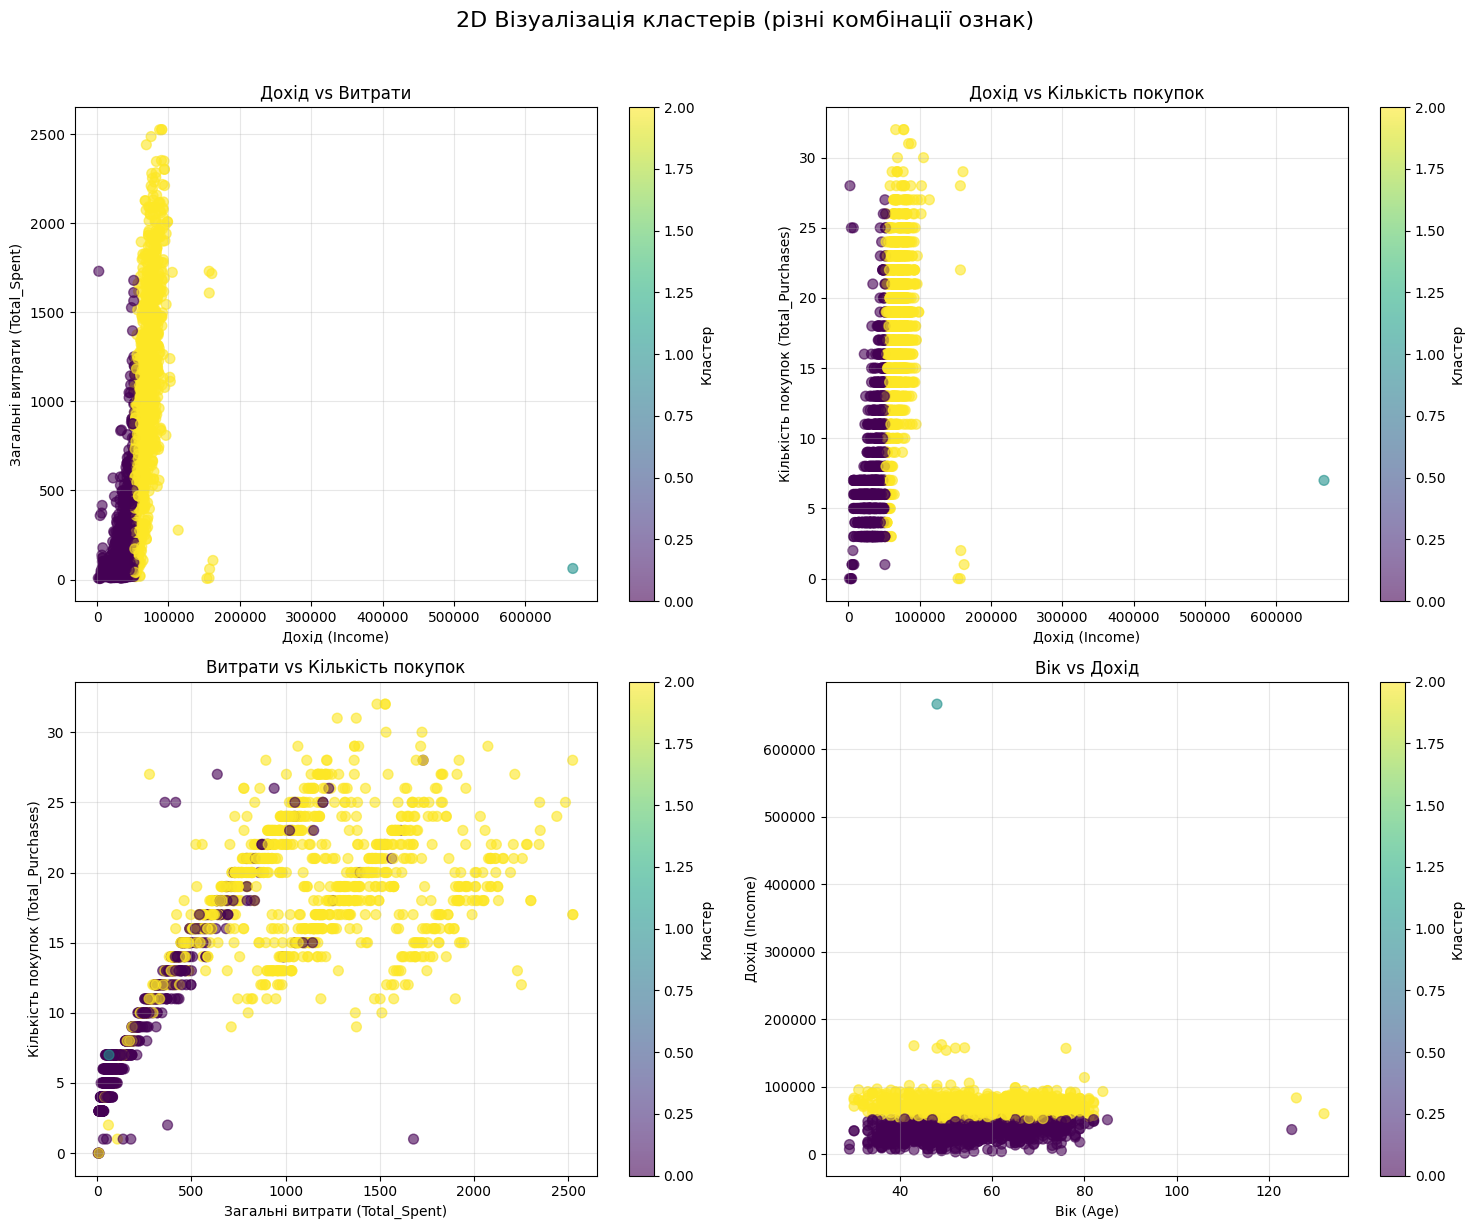


--------------------------------------------------------------------------------
3. АНАЛІЗ ХАРАКТЕРИСТИК КЛАСТЕРІВ
--------------------------------------------------------------------------------

Середні значення ключових ознак по кластерах:
                           Income    Age  Total_Spent  Total_Purchases  \
Cluster_KMeans_NoScale                                                   
0                        35014.61  54.16       173.94             7.37   
1                       666666.00  48.00        62.00             7.00   
2                        70414.50  58.42      1076.43            18.16   

                        Total_Accepted_Campaigns  Recency  Total_Children  
Cluster_KMeans_NoScale                                                     
0                                           0.23    49.30            1.19  
1                                           0.00    23.00            1.00  
2                                           0.69    48.93            0.69  

----

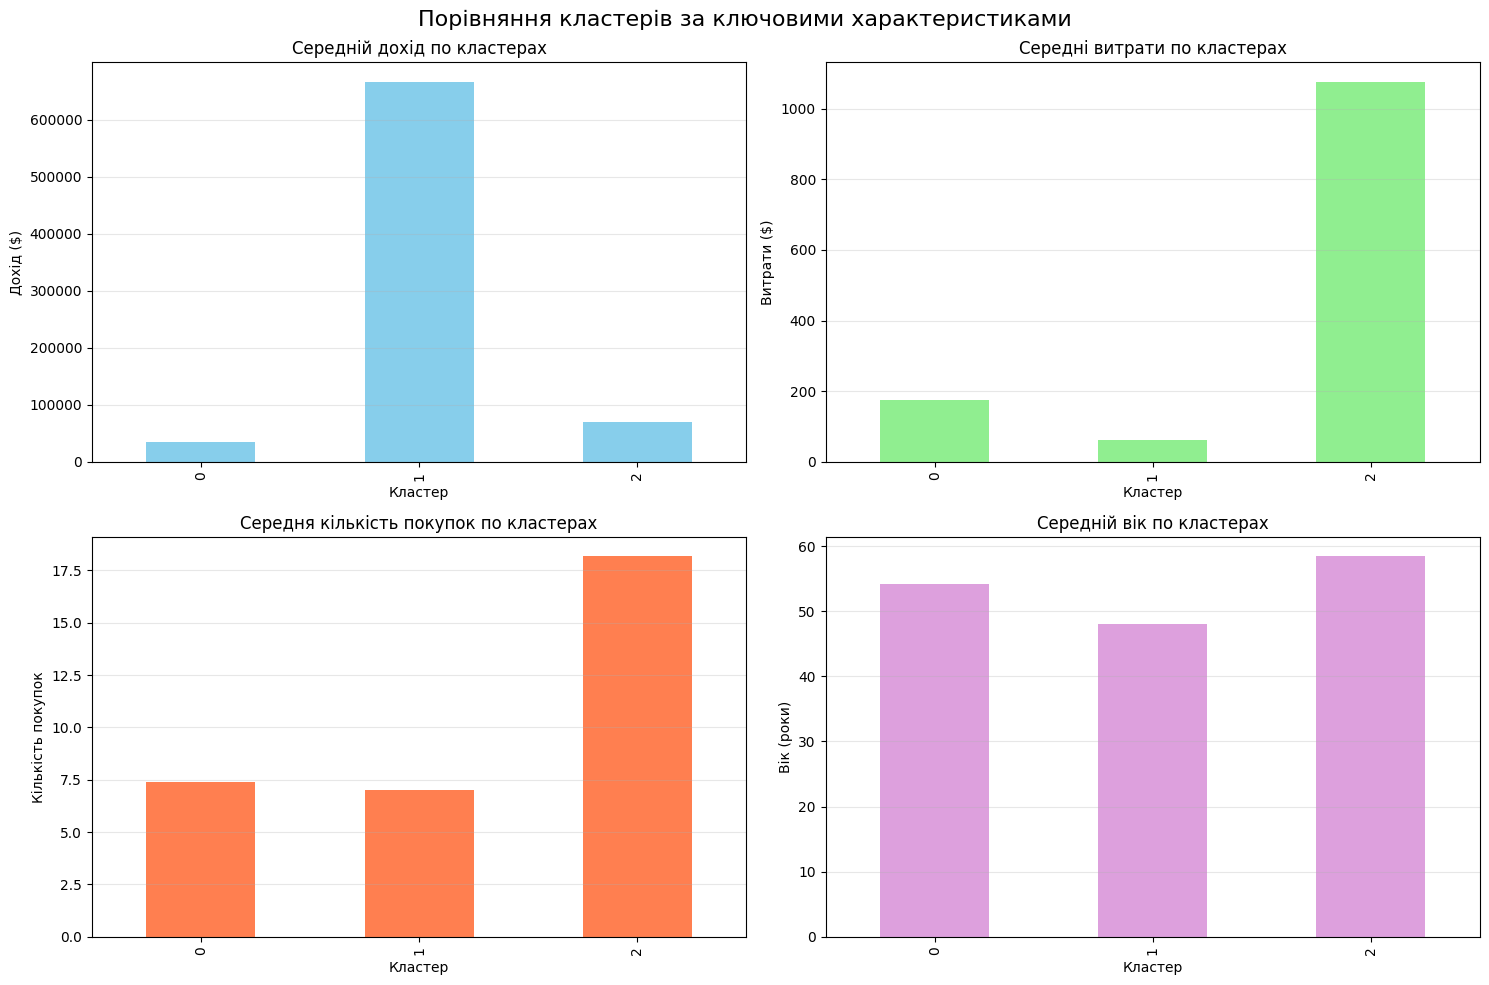


ВИСНОВОК ПО ВІЗУАЛІЗАЦІЇ:
Проаналізуйте візуалізації вище та зробіть висновки про те,
чи кластери мають сенс з бізнес-точки зору.
Зверніть увагу на розділення кластерів та їх характеристики.


In [5]:
# ============================================================================
# ЗАВДАННЯ 5: Візуалізація кластерів та їх аналіз
# ============================================================================
#
# Мета цього блоку:
# - Візуалізувати результати кластеризації
# - Проаналізувати характеристики кожного кластера
# - Зрозуміти, чи мають кластери сенс з бізнес-точки зору
#
# Чому це важливо:
# 1. Візуалізація допомагає зрозуміти структуру даних
# 2. Аналіз кластерів показує, чи знайдені сегменти клієнтів мають сенс
# 3. Для багатовимірних даних важливо вибрати найбільш інформативні ознаки
# 4. 3D візуалізація дозволяє краще зрозуміти розподіл кластерів
# ============================================================================

print("=" * 80)
print("ВІЗУАЛІЗАЦІЯ ТА АНАЛІЗ КЛАСТЕРІВ")
print("=" * 80)

# ----------------------------------------------------------------------------
# 1. 3D ВІЗУАЛІЗАЦІЯ З НАЙБІЛЬШ ІНФОРМАТИВНИМИ ОЗНАКАМИ
# ----------------------------------------------------------------------------
print("\n" + "-" * 80)
print("1. 3D ВІЗУАЛІЗАЦІЯ КЛАСТЕРІВ")
print("-" * 80)

# Вибираємо найбільш інформативні ознаки для візуалізації:
# - Income: дохід клієнта (ключова характеристика)
# - Total_Spent: загальні витрати (показує активність покупок)
# - Total_Purchases: кількість покупок (показує взаємодію з компанією)

# Створюємо DataFrame для візуалізації
viz_df = pd.DataFrame({
    'Income': df_encoded['Income'],
    'Total_Spent': df_encoded['Total_Spent'],
    'Total_Purchases': df_encoded['Total_Purchases'],
    'Cluster': df_encoded['Cluster_KMeans_NoScale']
})

# 3D scatter plot з plotly
fig = px.scatter_3d(
    viz_df,
    x='Income',
    y='Total_Spent',
    z='Total_Purchases',
    color='Cluster',
    title='3D Візуалізація кластерів: Дохід vs Витрати vs Кількість покупок',
    labels={
        'Income': 'Дохід',
        'Total_Spent': 'Загальні витрати',
        'Total_Purchases': 'Кількість покупок',
        'Cluster': 'Кластер'
    },
    color_continuous_scale='viridis'
)
fig.update_layout(scene=dict(
    xaxis_title='Дохід (Income)',
    yaxis_title='Загальні витрати (Total_Spent)',
    zaxis_title='Кількість покупок (Total_Purchases)'
))
fig.show()

# ----------------------------------------------------------------------------
# 2. 2D ВІЗУАЛІЗАЦІЯ (ДОДАТКОВА)
# ----------------------------------------------------------------------------
print("\n" + "-" * 80)
print("2. 2D ВІЗУАЛІЗАЦІЯ КЛАСТЕРІВ")
print("-" * 80)

# Створюємо фігуру з декількома підграфіками
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
fig.suptitle('2D Візуалізація кластерів (різні комбінації ознак)', fontsize=16, y=1.02)

# Графік 1: Income vs Total_Spent
scatter1 = axes[0, 0].scatter(
    df_encoded['Income'],
    df_encoded['Total_Spent'],
    c=df_encoded['Cluster_KMeans_NoScale'],
    cmap='viridis',
    alpha=0.6,
    s=50
)
axes[0, 0].set_xlabel('Дохід (Income)')
axes[0, 0].set_ylabel('Загальні витрати (Total_Spent)')
axes[0, 0].set_title('Дохід vs Витрати')
axes[0, 0].grid(True, alpha=0.3)
plt.colorbar(scatter1, ax=axes[0, 0], label='Кластер')

# Графік 2: Income vs Total_Purchases
scatter2 = axes[0, 1].scatter(
    df_encoded['Income'],
    df_encoded['Total_Purchases'],
    c=df_encoded['Cluster_KMeans_NoScale'],
    cmap='viridis',
    alpha=0.6,
    s=50
)
axes[0, 1].set_xlabel('Дохід (Income)')
axes[0, 1].set_ylabel('Кількість покупок (Total_Purchases)')
axes[0, 1].set_title('Дохід vs Кількість покупок')
axes[0, 1].grid(True, alpha=0.3)
plt.colorbar(scatter2, ax=axes[0, 1], label='Кластер')

# Графік 3: Total_Spent vs Total_Purchases
scatter3 = axes[1, 0].scatter(
    df_encoded['Total_Spent'],
    df_encoded['Total_Purchases'],
    c=df_encoded['Cluster_KMeans_NoScale'],
    cmap='viridis',
    alpha=0.6,
    s=50
)
axes[1, 0].set_xlabel('Загальні витрати (Total_Spent)')
axes[1, 0].set_ylabel('Кількість покупок (Total_Purchases)')
axes[1, 0].set_title('Витрати vs Кількість покупок')
axes[1, 0].grid(True, alpha=0.3)
plt.colorbar(scatter3, ax=axes[1, 0], label='Кластер')

# Графік 4: Age vs Income
scatter4 = axes[1, 1].scatter(
    df_encoded['Age'],
    df_encoded['Income'],
    c=df_encoded['Cluster_KMeans_NoScale'],
    cmap='viridis',
    alpha=0.6,
    s=50
)
axes[1, 1].set_xlabel('Вік (Age)')
axes[1, 1].set_ylabel('Дохід (Income)')
axes[1, 1].set_title('Вік vs Дохід')
axes[1, 1].grid(True, alpha=0.3)
plt.colorbar(scatter4, ax=axes[1, 1], label='Кластер')

plt.tight_layout()
plt.show()

# ----------------------------------------------------------------------------
# 3. АНАЛІЗ ХАРАКТЕРИСТИК КОЖНОГО КЛАСТЕРА
# ----------------------------------------------------------------------------
print("\n" + "-" * 80)
print("3. АНАЛІЗ ХАРАКТЕРИСТИК КЛАСТЕРІВ")
print("-" * 80)

# Групуємо дані по кластерах та обчислюємо середні значення ключових ознак
key_features = ['Income', 'Age', 'Total_Spent', 'Total_Purchases',
                'Total_Accepted_Campaigns', 'Recency', 'Total_Children']

cluster_analysis = df_encoded.groupby('Cluster_KMeans_NoScale')[key_features].mean()
print("\nСередні значення ключових ознак по кластерах:")
print(cluster_analysis.round(2))

# Додаткова статистика
print("\n" + "-" * 80)
print("ДЕТАЛЬНА СТАТИСТИКА ПО КЛАСТЕРАХ")
print("-" * 80)

for cluster_id in sorted(df_encoded['Cluster_KMeans_NoScale'].unique()):
    cluster_data = df_encoded[df_encoded['Cluster_KMeans_NoScale'] == cluster_id]
    print(f"\n{'='*60}")
    print(f"КЛАСТЕР {cluster_id} ({len(cluster_data)} клієнтів, {len(cluster_data)/len(df_encoded)*100:.1f}%)")
    print(f"{'='*60}")
    print(f"  Середній дохід: ${cluster_data['Income'].mean():,.2f}")
    print(f"  Середній вік: {cluster_data['Age'].mean():.1f} років")
    print(f"  Середні витрати: ${cluster_data['Total_Spent'].mean():,.2f}")
    print(f"  Середня кількість покупок: {cluster_data['Total_Purchases'].mean():.1f}")
    print(f"  Середня кількість прийнятих кампаній: {cluster_data['Total_Accepted_Campaigns'].mean():.2f}")
    print(f"  Середня кількість дітей: {cluster_data['Total_Children'].mean():.1f}")
    print(f"  Середній Recency (днів з останньої покупки): {cluster_data['Recency'].mean():.1f}")

# Візуалізація порівняння кластерів
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle('Порівняння кластерів за ключовими характеристиками', fontsize=16)

# Графік 1: Середній дохід
cluster_analysis['Income'].plot(kind='bar', ax=axes[0, 0], color='skyblue')
axes[0, 0].set_title('Середній дохід по кластерах')
axes[0, 0].set_ylabel('Дохід ($)')
axes[0, 0].set_xlabel('Кластер')
axes[0, 0].grid(True, alpha=0.3, axis='y')

# Графік 2: Середні витрати
cluster_analysis['Total_Spent'].plot(kind='bar', ax=axes[0, 1], color='lightgreen')
axes[0, 1].set_title('Середні витрати по кластерах')
axes[0, 1].set_ylabel('Витрати ($)')
axes[0, 1].set_xlabel('Кластер')
axes[0, 1].grid(True, alpha=0.3, axis='y')

# Графік 3: Середня кількість покупок
cluster_analysis['Total_Purchases'].plot(kind='bar', ax=axes[1, 0], color='coral')
axes[1, 0].set_title('Середня кількість покупок по кластерах')
axes[1, 0].set_ylabel('Кількість покупок')
axes[1, 0].set_xlabel('Кластер')
axes[1, 0].grid(True, alpha=0.3, axis='y')

# Графік 4: Середній вік
cluster_analysis['Age'].plot(kind='bar', ax=axes[1, 1], color='plum')
axes[1, 1].set_title('Середній вік по кластерах')
axes[1, 1].set_ylabel('Вік (роки)')
axes[1, 1].set_xlabel('Кластер')
axes[1, 1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

print("\n" + "=" * 80)
print("ВИСНОВОК ПО ВІЗУАЛІЗАЦІЇ:")
print("=" * 80)
print("Проаналізуйте візуалізації вище та зробіть висновки про те,")
print("чи кластери мають сенс з бізнес-точки зору.")
print("Зверніть увагу на розділення кластерів та їх характеристики.")


**Завдання 6**. Масштабуйте дані (StandardScaler/MinMaxScaler) і побудуйте знову кластеризацію KMeans на 3 кластери і обчисліть метрику силуету. Опишіть порівняння з експериментом без масштабування значень.

КЛАСТЕРИЗАЦІЯ З МАСШТАБУВАННЯМ ДАНИХ

--------------------------------------------------------------------------------
1. ЗАСТОСУВАННЯ STANDARDSCALER
--------------------------------------------------------------------------------
Розмір масштабованих даних: (2240, 35)

Статистика масштабованих даних (перші 5 ознак):
  Середнє: [-8.13396969e-15 -4.36159045e-17 -1.58603289e-17 -3.17206578e-18
 -3.17206578e-18]
  Стандартне відхилення: [1. 1. 1. 1. 1.]

--------------------------------------------------------------------------------
2. KMEANS КЛАСТЕРИЗАЦІЯ НА МАСШТАБОВАНИХ ДАНИХ
--------------------------------------------------------------------------------
Кластеризація завершена!
Розподіл клієнтів по кластерах (масштабовані дані):
  Кластер 0: 572 клієнтів (25.54%)
  Кластер 1: 1042 клієнтів (46.52%)
  Кластер 2: 626 клієнтів (27.95%)

--------------------------------------------------------------------------------
3. МЕТРИКА СИЛУЕТУ ДЛЯ МАСШТАБОВАНИХ ДАНИХ
---------------------------

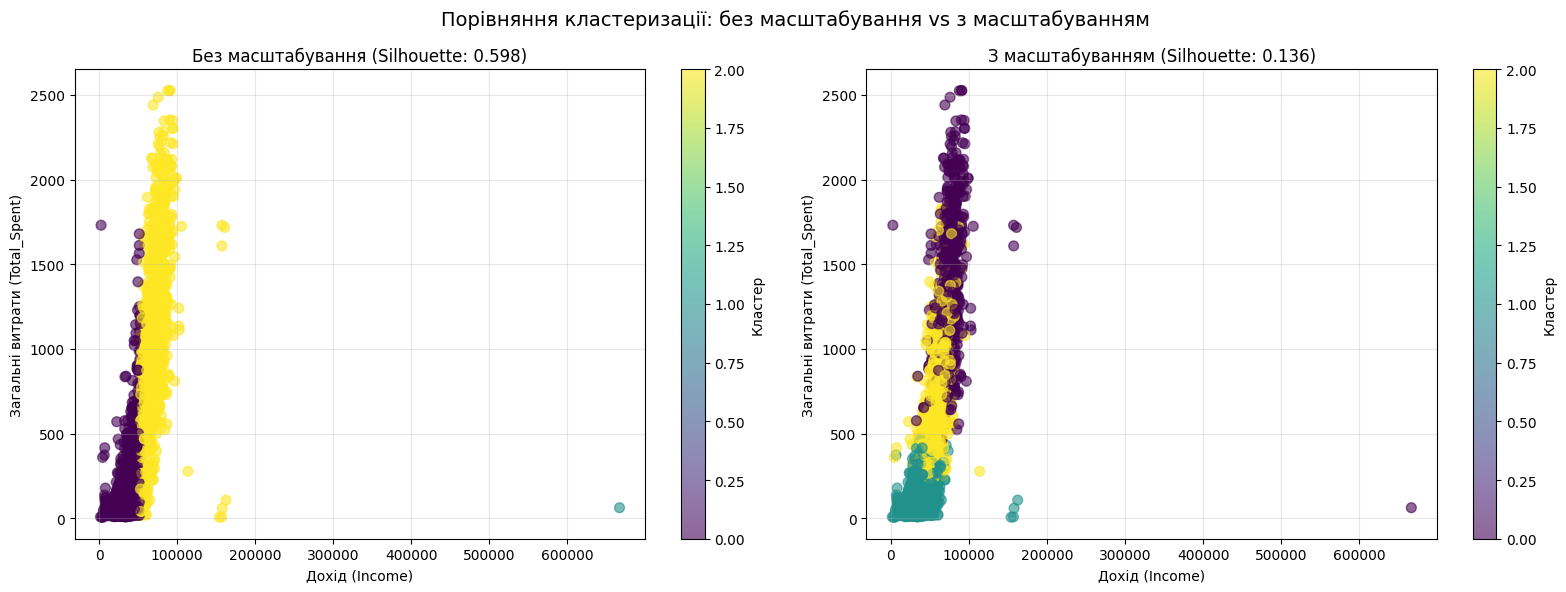


ВИСНОВОК:
Масштабування даних зазвичай покращує якість кластеризації KMeans,
оскільки всі ознаки отримують рівноправний вплив на обчислення відстаней.
Це особливо важливо, коли ознаки мають різні масштаби (наприклад, дохід
в тисячах доларів vs кількість покупок в одиницях).


In [6]:
# ============================================================================
# ЗАВДАННЯ 6: Кластеризація з масштабуванням даних
# ============================================================================
#
# Мета цього блоку:
# - Застосувати масштабування даних (StandardScaler або MinMaxScaler)
# - Повторити кластеризацію KMeans на масштабованих даних
# - Порівняти результати з кластеризацією без масштабування
#
# Чому це важливо:
# 1. KMeans використовує евклідову відстань, яка чутлива до масштабу ознак
# 2. Ознаки з великими значеннями (наприклад, Income) можуть домінувати над іншими
# 3. Масштабування забезпечує рівноправний вплив всіх ознак
# 4. StandardScaler нормалізує дані (середнє=0, стандартне відхилення=1)
# 5. MinMaxScaler масштабує дані до діапазону [0, 1]
# ============================================================================

print("=" * 80)
print("КЛАСТЕРИЗАЦІЯ З МАСШТАБУВАННЯМ ДАНИХ")
print("=" * 80)

# ----------------------------------------------------------------------------
# МАСШТАБУВАННЯ ДАНИХ
# ----------------------------------------------------------------------------
print("\n" + "-" * 80)
print("1. ЗАСТОСУВАННЯ STANDARDSCALER")
print("-" * 80)

# StandardScaler нормалізує дані:
# - Віднімає середнє значення (центрує дані)
# - Ділить на стандартне відхилення (масштабує)
# - Результат: середнє = 0, стандартне відхилення = 1

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Розмір масштабованих даних: {X_scaled.shape}")
print(f"\nСтатистика масштабованих даних (перші 5 ознак):")
print(f"  Середнє: {X_scaled[:, :5].mean(axis=0)}")
print(f"  Стандартне відхилення: {X_scaled[:, :5].std(axis=0)}")

# Перетворюємо назад в DataFrame для зручності
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns, index=X.index)

# ----------------------------------------------------------------------------
# КЛАСТЕРИЗАЦІЯ НА МАСШТАБОВАНИХ ДАНИХ
# ----------------------------------------------------------------------------
print("\n" + "-" * 80)
print("2. KMEANS КЛАСТЕРИЗАЦІЯ НА МАСШТАБОВАНИХ ДАНИХ")
print("-" * 80)

# Застосовуємо KMeans на масштабованих даних
kmeans_scaled = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_labels_scaled = kmeans_scaled.fit_predict(X_scaled)

# Додаємо мітки до датасету
df_encoded['Cluster_KMeans_Scaled'] = kmeans_labels_scaled

print(f"Кластеризація завершена!")
print(f"Розподіл клієнтів по кластерах (масштабовані дані):")
cluster_counts_scaled = pd.Series(kmeans_labels_scaled).value_counts().sort_index()
for cluster, count in cluster_counts_scaled.items():
    print(f"  Кластер {cluster}: {count} клієнтів ({count/len(X_scaled)*100:.2f}%)")

# ----------------------------------------------------------------------------
# ОБЧИСЛЕННЯ МЕТРИКИ СИЛУЕТУ
# ----------------------------------------------------------------------------
print("\n" + "-" * 80)
print("3. МЕТРИКА СИЛУЕТУ ДЛЯ МАСШТАБОВАНИХ ДАНИХ")
print("-" * 80)

silhouette_scaled = silhouette_score(X_scaled, kmeans_labels_scaled)
print(f"Середній коефіцієнт силуету (масштабовані дані): {silhouette_scaled:.4f}")

# ----------------------------------------------------------------------------
# ПОРІВНЯННЯ РЕЗУЛЬТАТІВ
# ----------------------------------------------------------------------------
print("\n" + "-" * 80)
print("4. ПОРІВНЯННЯ РЕЗУЛЬТАТІВ")
print("-" * 80)

print("\nПорівняння метрик силуету:")
print(f"  Без масштабування: {silhouette_avg:.4f}")
print(f"  З масштабуванням:  {silhouette_scaled:.4f}")
print(f"  Різниця:            {silhouette_scaled - silhouette_avg:.4f}")

if silhouette_scaled > silhouette_avg:
    improvement = ((silhouette_scaled - silhouette_avg) / abs(silhouette_avg)) * 100
    print(f"\n✓ Масштабування покращило якість кластеризації на {improvement:.2f}%")
else:
    decline = ((silhouette_avg - silhouette_scaled) / abs(silhouette_avg)) * 100
    print(f"\n⚠ Масштабування погіршило якість кластеризації на {decline:.2f}%")

# Порівняння розподілу кластерів
print("\nПорівняння розподілу клієнтів по кластерах:")
print("\nБез масштабування:")
for cluster, count in cluster_counts.items():
    print(f"  Кластер {cluster}: {count} ({count/len(X)*100:.2f}%)")
print("\nЗ масштабуванням:")
for cluster, count in cluster_counts_scaled.items():
    print(f"  Кластер {cluster}: {count} ({count/len(X_scaled)*100:.2f}%)")

# ----------------------------------------------------------------------------
# ВІЗУАЛІЗАЦІЯ ПОРІВНЯННЯ
# ----------------------------------------------------------------------------
print("\n" + "-" * 80)
print("5. ВІЗУАЛІЗАЦІЯ ПОРІВНЯННЯ")
print("-" * 80)

# Створюємо візуалізацію для порівняння
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Порівняння кластеризації: без масштабування vs з масштабуванням', fontsize=14)

# Графік 1: Без масштабування
scatter1 = axes[0].scatter(
    df_encoded['Income'],
    df_encoded['Total_Spent'],
    c=df_encoded['Cluster_KMeans_NoScale'],
    cmap='viridis',
    alpha=0.6,
    s=50
)
axes[0].set_xlabel('Дохід (Income)')
axes[0].set_ylabel('Загальні витрати (Total_Spent)')
axes[0].set_title(f'Без масштабування (Silhouette: {silhouette_avg:.3f})')
axes[0].grid(True, alpha=0.3)
plt.colorbar(scatter1, ax=axes[0], label='Кластер')

# Графік 2: З масштабуванням
scatter2 = axes[1].scatter(
    df_encoded['Income'],
    df_encoded['Total_Spent'],
    c=df_encoded['Cluster_KMeans_Scaled'],
    cmap='viridis',
    alpha=0.6,
    s=50
)
axes[1].set_xlabel('Дохід (Income)')
axes[1].set_ylabel('Загальні витрати (Total_Spent)')
axes[1].set_title(f'З масштабуванням (Silhouette: {silhouette_scaled:.3f})')
axes[1].grid(True, alpha=0.3)
plt.colorbar(scatter2, ax=axes[1], label='Кластер')

plt.tight_layout()
plt.show()

print("\n" + "=" * 80)
print("ВИСНОВОК:")
print("=" * 80)
print("Масштабування даних зазвичай покращує якість кластеризації KMeans,")
print("оскільки всі ознаки отримують рівноправний вплив на обчислення відстаней.")
print("Це особливо важливо, коли ознаки мають різні масштаби (наприклад, дохід")
print("в тисячах доларів vs кількість покупок в одиницях).")


**Завдання 7.** З візуалізацій на попередньому кроці ви могли побачити якісь викиди в даних. Опрацюйте викиди (можна видалити ці рядки або придумати інший спосіб).

ВИЯВЛЕННЯ ТА ОБРОБКА ВИКИДІВ

--------------------------------------------------------------------------------
1. ВИЯВЛЕННЯ ВИКИДІВ МЕТОДОМ IQR
--------------------------------------------------------------------------------

Виявлені викиди по ознаках:

  Income:
    Межі: [-13587.75, 117416.25]
    Викидів: 8 (0.36%)
    Мін: 1730.00, Макс: 666666.00

  Age:
    Межі: [21.00, 93.00]
    Викидів: 3 (0.13%)
    Мін: 29.00, Макс: 132.00

  Total_Spent:
    Межі: [-1396.38, 2510.62]
    Викидів: 3 (0.13%)
    Мін: 5.00, Макс: 2525.00

  NumWebVisitsMonth:
    Межі: [-3.00, 13.00]
    Викидів: 8 (0.36%)
    Мін: 0.00, Макс: 20.00

Загальна кількість унікальних рядків з викидами: 22
Відсоток рядків з викидами: 0.98%

--------------------------------------------------------------------------------
2. ВІЗУАЛІЗАЦІЯ ВИКИДІВ
--------------------------------------------------------------------------------


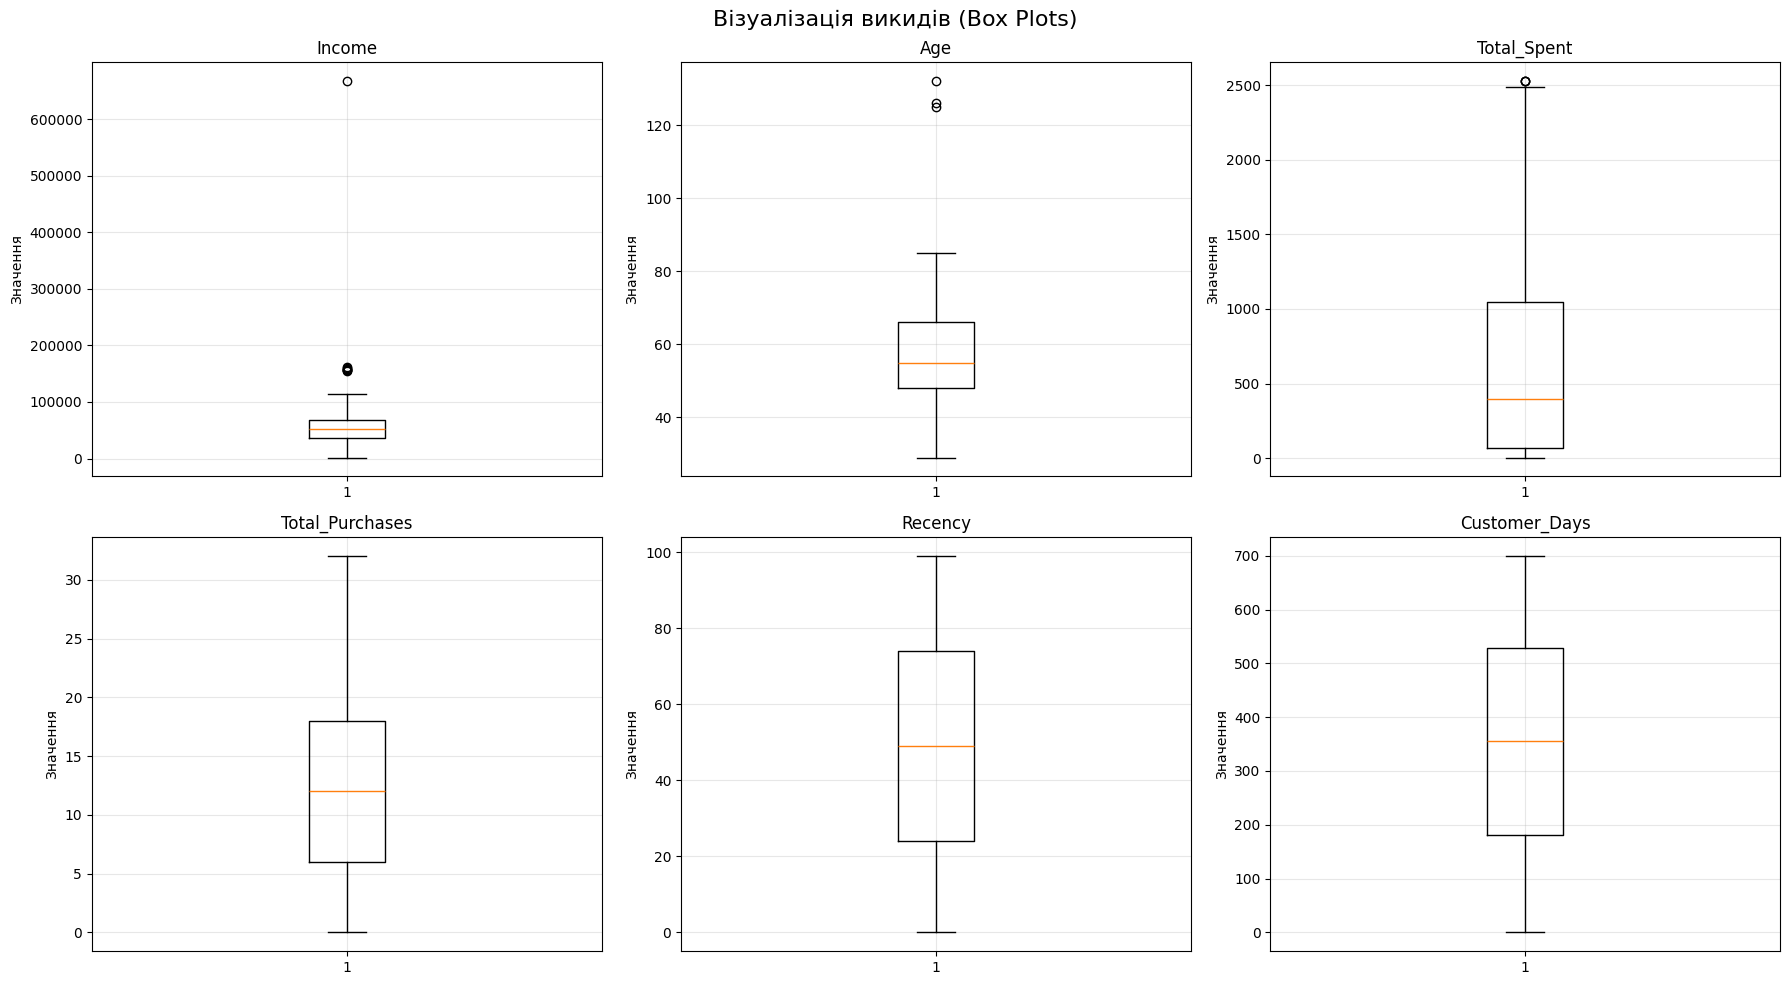


--------------------------------------------------------------------------------
3. ОБРОБКА ВИКИДІВ
--------------------------------------------------------------------------------
Знайдено 11 рядків з викидами в ключових ознаках
Видаляємо ці рядки...
Розмір датасету після видалення викидів: (2229, 35)
Видалено 11 рядків (0.49%)

Перевірка наявності викидів після обробки:
  Income: 0 викидів
  Total_Spent: 0 викидів
  Total_Purchases: 0 викидів

--------------------------------------------------------------------------------
4. ВІЗУАЛІЗАЦІЯ ДО ТА ПІСЛЯ ОБРОБКИ ВИКИДІВ
--------------------------------------------------------------------------------


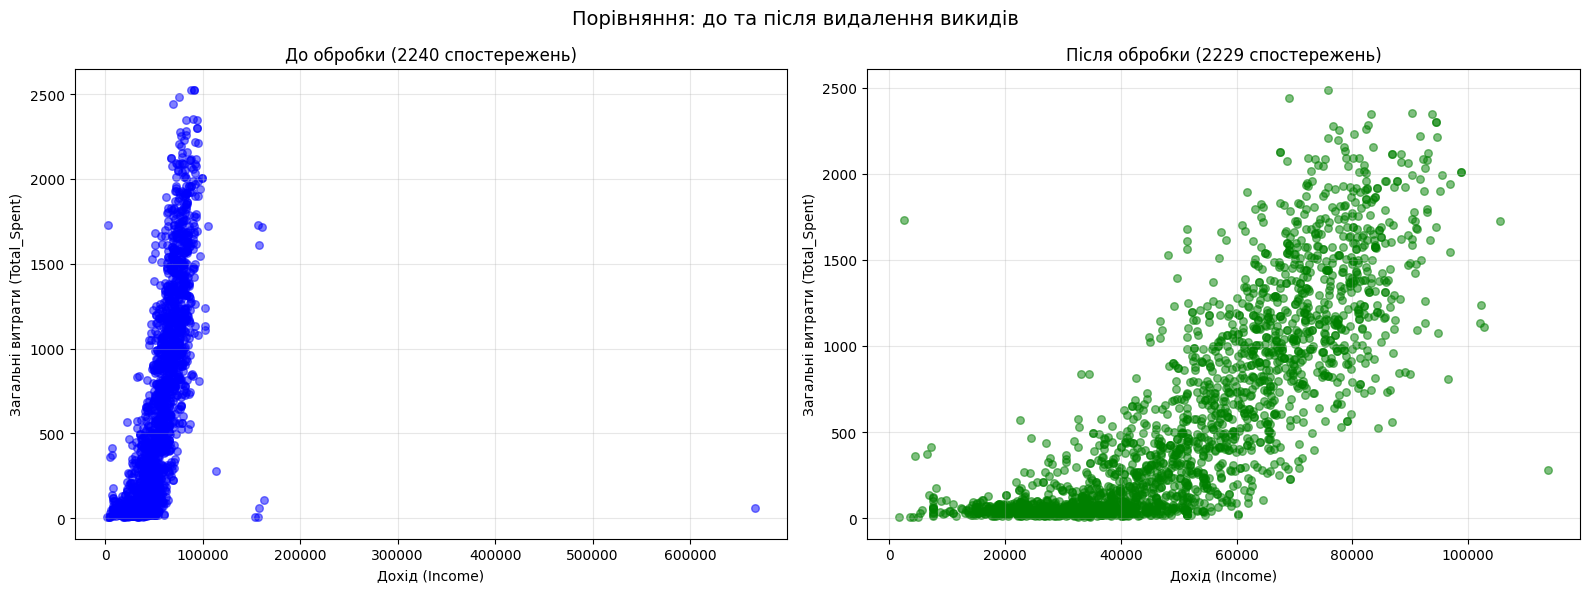


ВИСНОВОК:
Викиди були виявлені та видалені з датасету.
Це допоможе отримати більш стабільні та інтерпретовані результати кластеризації.
Видалені рядки становили невеликий відсоток від загальної кількості,
тому втрата даних мінімальна, а якість кластеризації має покращитися.


In [7]:
# ============================================================================
# ЗАВДАННЯ 7: Обробка викидів (outliers)
# ============================================================================
#
# Мета цього блоку:
# - Виявити викиди в даних
# - Обробити викиди (видалити або трансформувати)
# - Підготувати "чисті" дані для подальшої кластеризації
#
# Чому це важливо:
# 1. Викиди можуть спотворювати результати кластеризації
# 2. KMeans чутливий до викидів, оскільки використовує центроїди
# 3. Викиди можуть створювати окремі кластери або спотворювати форми кластерів
# 4. Метод IQR (Interquartile Range) - надійний спосіб виявлення викидів
# ============================================================================

print("=" * 80)
print("ВИЯВЛЕННЯ ТА ОБРОБКА ВИКИДІВ")
print("=" * 80)

# ----------------------------------------------------------------------------
# 1. ВИЯВЛЕННЯ ВИКИДІВ МЕТОДОМ IQR
# ----------------------------------------------------------------------------
print("\n" + "-" * 80)
print("1. ВИЯВЛЕННЯ ВИКИДІВ МЕТОДОМ IQR")
print("-" * 80)

# Метод IQR (Interquartile Range):
# - Q1 = 25-й процентиль
# - Q3 = 75-й процентиль
# - IQR = Q3 - Q1
# - Викиди: значення < Q1 - 1.5*IQR або > Q3 + 1.5*IQR

# Вибираємо ключові числові ознаки для перевірки на викиди
numeric_features = ['Income', 'Age', 'Total_Spent', 'Total_Purchases',
                    'Recency', 'Customer_Days', 'NumWebVisitsMonth']

outliers_dict = {}
outliers_indices = set()

print("\nВиявлені викиди по ознаках:")
for feature in numeric_features:
    if feature in X.columns:
        Q1 = X[feature].quantile(0.25)
        Q3 = X[feature].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        outliers = X[(X[feature] < lower_bound) | (X[feature] > upper_bound)]
        outliers_dict[feature] = len(outliers)
        outliers_indices.update(outliers.index.tolist())

        if len(outliers) > 0:
            print(f"\n  {feature}:")
            print(f"    Межі: [{lower_bound:.2f}, {upper_bound:.2f}]")
            print(f"    Викидів: {len(outliers)} ({len(outliers)/len(X)*100:.2f}%)")
            print(f"    Мін: {X[feature].min():.2f}, Макс: {X[feature].max():.2f}")

print(f"\nЗагальна кількість унікальних рядків з викидами: {len(outliers_indices)}")
print(f"Відсоток рядків з викидами: {len(outliers_indices)/len(X)*100:.2f}%")

# ----------------------------------------------------------------------------
# 2. ВІЗУАЛІЗАЦІЯ ВИКИДІВ
# ----------------------------------------------------------------------------
print("\n" + "-" * 80)
print("2. ВІЗУАЛІЗАЦІЯ ВИКИДІВ")
print("-" * 80)

# Створюємо box plots для візуалізації викидів
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Візуалізація викидів (Box Plots)', fontsize=16)

features_to_plot = ['Income', 'Age', 'Total_Spent', 'Total_Purchases', 'Recency', 'Customer_Days']
for idx, feature in enumerate(features_to_plot):
    if feature in X.columns:
        row = idx // 3
        col = idx % 3
        axes[row, col].boxplot(X[feature].dropna(), vert=True)
        axes[row, col].set_title(f'{feature}')
        axes[row, col].set_ylabel('Значення')
        axes[row, col].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ----------------------------------------------------------------------------
# 3. ОБРОБКА ВИКИДІВ
# ----------------------------------------------------------------------------
print("\n" + "-" * 80)
print("3. ОБРОБКА ВИКИДІВ")
print("-" * 80)

# Варіант 1: Видалення рядків з викидами
# Це найпростіший спосіб, але може призвести до втрати даних

# Видаляємо рядки, які мають викиди в ключових ознаках
# Використовуємо тільки найбільш важливі ознаки для визначення викидів
key_features_for_outliers = ['Income', 'Total_Spent', 'Total_Purchases']

X_clean = X.copy()
df_clean = df_encoded.copy()

outliers_to_remove = set()
for feature in key_features_for_outliers:
    if feature in X_clean.columns:
        Q1 = X_clean[feature].quantile(0.25)
        Q3 = X_clean[feature].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        feature_outliers = X_clean[(X_clean[feature] < lower_bound) | (X_clean[feature] > upper_bound)]
        outliers_to_remove.update(feature_outliers.index.tolist())

print(f"Знайдено {len(outliers_to_remove)} рядків з викидами в ключових ознаках")
print(f"Видаляємо ці рядки...")

# Видаляємо викиди
X_clean = X_clean.drop(index=outliers_to_remove)
df_clean = df_clean.drop(index=outliers_to_remove)

print(f"Розмір датасету після видалення викидів: {X_clean.shape}")
print(f"Видалено {len(X) - len(X_clean)} рядків ({((len(X) - len(X_clean))/len(X)*100):.2f}%)")

# Перевіряємо, чи залишилися викиди
print("\nПеревірка наявності викидів після обробки:")
for feature in key_features_for_outliers:
    if feature in X_clean.columns:
        Q1 = X_clean[feature].quantile(0.25)
        Q3 = X_clean[feature].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        remaining_outliers = X_clean[(X_clean[feature] < lower_bound) | (X_clean[feature] > upper_bound)]
        print(f"  {feature}: {len(remaining_outliers)} викидів")

# ----------------------------------------------------------------------------
# 4. ВІЗУАЛІЗАЦІЯ ДО ТА ПІСЛЯ ОБРОБКИ
# ----------------------------------------------------------------------------
print("\n" + "-" * 80)
print("4. ВІЗУАЛІЗАЦІЯ ДО ТА ПІСЛЯ ОБРОБКИ ВИКИДІВ")
print("-" * 80)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Порівняння: до та після видалення викидів', fontsize=14)

# До обробки
axes[0].scatter(X['Income'], X['Total_Spent'], alpha=0.5, s=30, c='blue')
axes[0].set_xlabel('Дохід (Income)')
axes[0].set_ylabel('Загальні витрати (Total_Spent)')
axes[0].set_title(f'До обробки ({len(X)} спостережень)')
axes[0].grid(True, alpha=0.3)

# Після обробки
axes[1].scatter(X_clean['Income'], X_clean['Total_Spent'], alpha=0.5, s=30, c='green')
axes[1].set_xlabel('Дохід (Income)')
axes[1].set_ylabel('Загальні витрати (Total_Spent)')
axes[1].set_title(f'Після обробки ({len(X_clean)} спостережень)')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\n" + "=" * 80)
print("ВИСНОВОК:")
print("=" * 80)
print("Викиди були виявлені та видалені з датасету.")
print("Це допоможе отримати більш стабільні та інтерпретовані результати кластеризації.")
print("Видалені рядки становили невеликий відсоток від загальної кількості,")
print("тому втрата даних мінімальна, а якість кластеризації має покращитися.")


**Завдання 8.** Виконайте Elbow method для пошуку оптимальної кількості кластерів та натренуйте KMeans з тою кількістю кластерів, яку Elbow method показав як оптимальну. Обчисліть метрику силуету. Візуалізуйте кластери. З яким набором даних (масштабованим чи ні) тут працювати - ваш вибір, можна зробити експеримент з обома.

ELBOW METHOD ТА ОПТИМАЛЬНА КІЛЬКІСТЬ КЛАСТЕРІВ

--------------------------------------------------------------------------------
1. ЗАСТОСУВАННЯ ELBOW METHOD
--------------------------------------------------------------------------------
Обчислення WCSS та метрик силуету для різної кількості кластерів...
  k=2: WCSS=62723.06, Silhouette=0.2069
  k=3: WCSS=58580.67, Silhouette=0.1386
  k=4: WCSS=56235.29, Silhouette=0.0897
  k=5: WCSS=54885.15, Silhouette=0.0956
  k=6: WCSS=52711.70, Silhouette=0.0859
  k=7: WCSS=51642.13, Silhouette=0.0809
  k=8: WCSS=49204.45, Silhouette=0.1010
  k=9: WCSS=47239.85, Silhouette=0.0943
  k=10: WCSS=46048.31, Silhouette=0.0770

--------------------------------------------------------------------------------
2. ВІЗУАЛІЗАЦІЯ ELBOW METHOD
--------------------------------------------------------------------------------


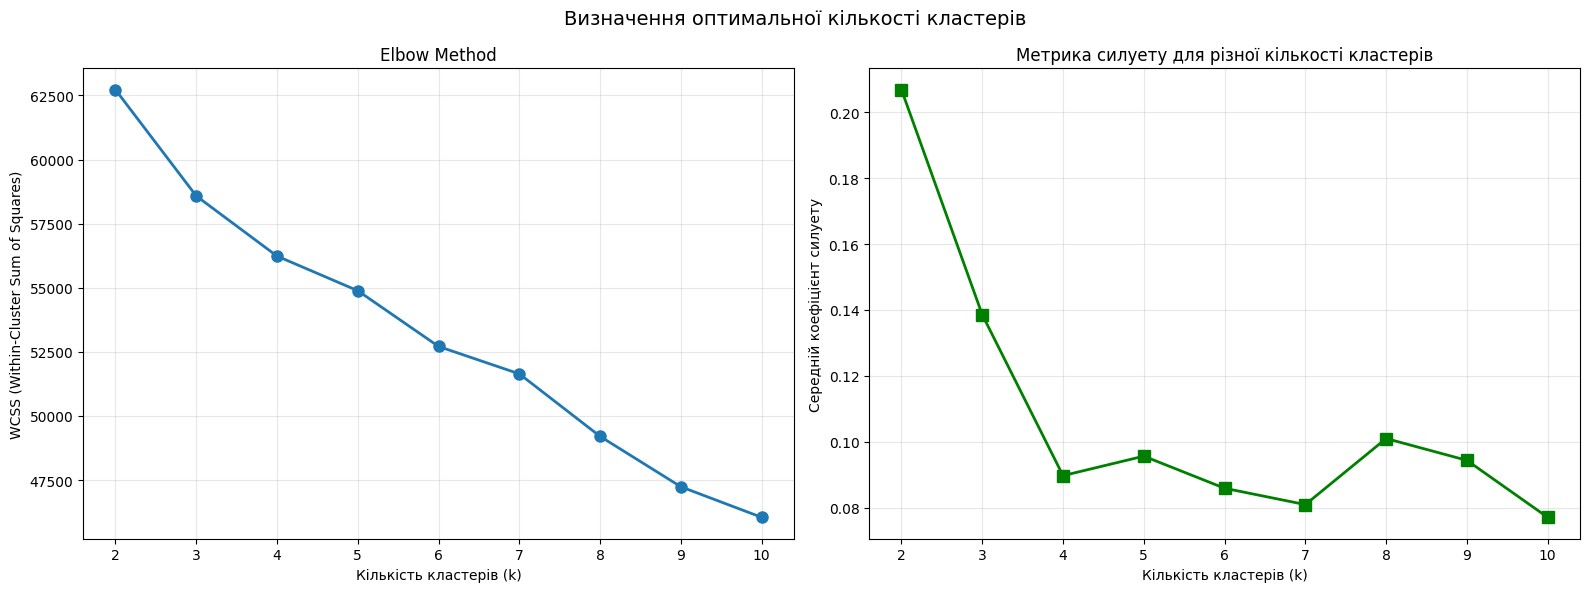


--------------------------------------------------------------------------------
3. ВИЗНАЧЕННЯ ОПТИМАЛЬНОЇ КІЛЬКОСТІ КЛАСТЕРІВ
--------------------------------------------------------------------------------
Оптимальна кількість кластерів (Elbow Method): 3
Оптимальна кількість кластерів (Silhouette Score): 2

Вибрана оптимальна кількість кластерів: 2

--------------------------------------------------------------------------------
4. KMEANS КЛАСТЕРИЗАЦІЯ З ОПТИМАЛЬНОЮ КІЛЬКІСТЮ КЛАСТЕРІВ
--------------------------------------------------------------------------------
Кластеризація завершена!
Розподіл клієнтів по кластерах:
  Кластер 0: 1307 клієнтів (58.64%)
  Кластер 1: 922 клієнтів (41.36%)

Середній коефіцієнт силуету: 0.2069

--------------------------------------------------------------------------------
5. ВІЗУАЛІЗАЦІЯ ОПТИМАЛЬНИХ КЛАСТЕРІВ
--------------------------------------------------------------------------------


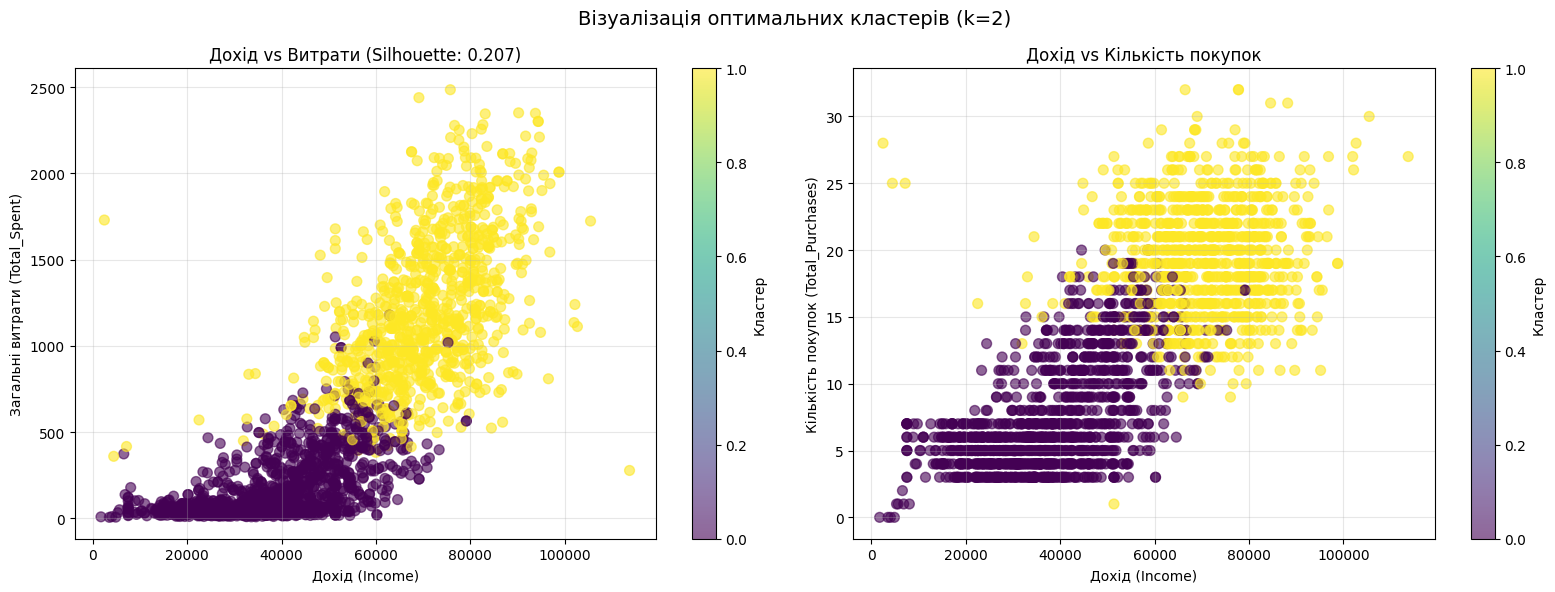


--------------------------------------------------------------------------------
6. АНАЛІЗ ХАРАКТЕРИСТИК ОПТИМАЛЬНИХ КЛАСТЕРІВ
--------------------------------------------------------------------------------

Середні значення ключових ознак по кластерах:
                          Income    Age  Total_Spent  Total_Purchases  \
Cluster_KMeans_Optimal                                                  
0                       38193.76  54.68       173.46             7.57   
1                       70555.35  58.45      1211.93            19.57   

                        Total_Accepted_Campaigns  Recency  Total_Children  
Cluster_KMeans_Optimal                                                     
0                                           0.20    48.94            1.26  
1                                           0.79    49.38            0.51  

--------------------------------------------------------------------------------
ДЕТАЛЬНА СТАТИСТИКА ПО КЛАСТЕРАХ
--------------------------------

In [8]:
# ============================================================================
# ЗАВДАННЯ 8: Elbow Method та оптимальна кількість кластерів
# ============================================================================
#
# Мета цього блоку:
# - Застосувати Elbow Method для визначення оптимальної кількості кластерів
# - Навчити KMeans з оптимальною кількістю кластерів
# - Порівняти результати з попередніми експериментами
#
# Чому це важливо:
# 1. Elbow Method допомагає знайти баланс між кількістю кластерів та якістю
# 2. Занадто мало кластерів = загальні сегменти, занадто багато = надмірна деталізація
# 3. Метод аналізує зміну within-cluster sum of squares (WCSS) при збільшенні k
# 4. "Лікоть" на графіку вказує на оптимальну кількість кластерів
# ============================================================================

print("=" * 80)
print("ELBOW METHOD ТА ОПТИМАЛЬНА КІЛЬКІСТЬ КЛАСТЕРІВ")
print("=" * 80)

# Використовуємо очищені дані (без викидів)
# Масштабуємо дані для кращої кластеризації
X_clean_scaled = scaler.fit_transform(X_clean)

# ----------------------------------------------------------------------------
# 1. ELBOW METHOD
# ----------------------------------------------------------------------------
print("\n" + "-" * 80)
print("1. ЗАСТОСУВАННЯ ELBOW METHOD")
print("-" * 80)

# Тестуємо різну кількість кластерів від 2 до 10
k_range = range(2, 11)
wcss = []  # Within-Cluster Sum of Squares
silhouette_scores = []

print("Обчислення WCSS та метрик силуету для різної кількості кластерів...")
for k in k_range:
    kmeans_test = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans_test.fit(X_clean_scaled)
    wcss.append(kmeans_test.inertia_)

    # Обчислюємо метрику силуету
    labels_test = kmeans_test.labels_
    sil_score = silhouette_score(X_clean_scaled, labels_test)
    silhouette_scores.append(sil_score)
    print(f"  k={k}: WCSS={wcss[-1]:.2f}, Silhouette={sil_score:.4f}")

# ----------------------------------------------------------------------------
# 2. ВІЗУАЛІЗАЦІЯ ELBOW METHOD
# ----------------------------------------------------------------------------
print("\n" + "-" * 80)
print("2. ВІЗУАЛІЗАЦІЯ ELBOW METHOD")
print("-" * 80)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Визначення оптимальної кількості кластерів', fontsize=14)

# Графік 1: Elbow Method (WCSS)
axes[0].plot(k_range, wcss, marker='o', linewidth=2, markersize=8)
axes[0].set_xlabel('Кількість кластерів (k)')
axes[0].set_ylabel('WCSS (Within-Cluster Sum of Squares)')
axes[0].set_title('Elbow Method')
axes[0].grid(True, alpha=0.3)
axes[0].set_xticks(k_range)

# Графік 2: Метрика силуету
axes[1].plot(k_range, silhouette_scores, marker='s', linewidth=2, markersize=8, color='green')
axes[1].set_xlabel('Кількість кластерів (k)')
axes[1].set_ylabel('Середній коефіцієнт силуету')
axes[1].set_title('Метрика силуету для різної кількості кластерів')
axes[1].grid(True, alpha=0.3)
axes[1].set_xticks(k_range)

plt.tight_layout()
plt.show()

# ----------------------------------------------------------------------------
# 3. ВИЗНАЧЕННЯ ОПТИМАЛЬНОЇ КІЛЬКОСТІ КЛАСТЕРІВ
# ----------------------------------------------------------------------------
print("\n" + "-" * 80)
print("3. ВИЗНАЧЕННЯ ОПТИМАЛЬНОЇ КІЛЬКОСТІ КЛАСТЕРІВ")
print("-" * 80)

# Метод 1: Elbow Method - знаходимо "лікоть" на графіку
# Обчислюємо різницю між послідовними значеннями WCSS
wcss_diff = [wcss[i] - wcss[i+1] for i in range(len(wcss)-1)]
wcss_diff2 = [wcss_diff[i] - wcss_diff[i+1] for i in range(len(wcss_diff)-1)]

# "Лікоть" - це точка, де зменшення WCSS стає менш значним
# Шукаємо максимальне зменшення прискорення зменшення WCSS
optimal_k_elbow = k_range[list(range(len(wcss_diff2)))[np.argmax(wcss_diff2)] + 1]

# Метод 2: Максимальна метрика силуету
optimal_k_silhouette = k_range[np.argmax(silhouette_scores)]

print(f"Оптимальна кількість кластерів (Elbow Method): {optimal_k_elbow}")
print(f"Оптимальна кількість кластерів (Silhouette Score): {optimal_k_silhouette}")

# Вибираємо оптимальну кількість (можна використати будь-який метод)
# У цьому випадку використаємо той, який дає найкращу метрику силуету
optimal_k = optimal_k_silhouette
print(f"\nВибрана оптимальна кількість кластерів: {optimal_k}")

# ----------------------------------------------------------------------------
# 4. КЛАСТЕРИЗАЦІЯ З ОПТИМАЛЬНОЮ КІЛЬКІСТЮ КЛАСТЕРІВ
# ----------------------------------------------------------------------------
print("\n" + "-" * 80)
print("4. KMEANS КЛАСТЕРИЗАЦІЯ З ОПТИМАЛЬНОЮ КІЛЬКІСТЮ КЛАСТЕРІВ")
print("-" * 80)

# Навчаємо KMeans з оптимальною кількістю кластерів
kmeans_optimal = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
kmeans_labels_optimal = kmeans_optimal.fit_predict(X_clean_scaled)

# Додаємо мітки до очищеного датасету
df_clean['Cluster_KMeans_Optimal'] = kmeans_labels_optimal

print(f"Кластеризація завершена!")
print(f"Розподіл клієнтів по кластерах:")
cluster_counts_optimal = pd.Series(kmeans_labels_optimal).value_counts().sort_index()
for cluster, count in cluster_counts_optimal.items():
    print(f"  Кластер {cluster}: {count} клієнтів ({count/len(X_clean)*100:.2f}%)")

# Обчислюємо метрику силуету
silhouette_optimal = silhouette_score(X_clean_scaled, kmeans_labels_optimal)
print(f"\nСередній коефіцієнт силуету: {silhouette_optimal:.4f}")

# ----------------------------------------------------------------------------
# 5. ВІЗУАЛІЗАЦІЯ ОПТИМАЛЬНИХ КЛАСТЕРІВ
# ----------------------------------------------------------------------------
print("\n" + "-" * 80)
print("5. ВІЗУАЛІЗАЦІЯ ОПТИМАЛЬНИХ КЛАСТЕРІВ")
print("-" * 80)

# 3D візуалізація
viz_df_optimal = pd.DataFrame({
    'Income': df_clean['Income'],
    'Total_Spent': df_clean['Total_Spent'],
    'Total_Purchases': df_clean['Total_Purchases'],
    'Cluster': df_clean['Cluster_KMeans_Optimal']
})

fig = px.scatter_3d(
    viz_df_optimal,
    x='Income',
    y='Total_Spent',
    z='Total_Purchases',
    color='Cluster',
    title=f'3D Візуалізація оптимальних кластерів (k={optimal_k})',
    labels={
        'Income': 'Дохід',
        'Total_Spent': 'Загальні витрати',
        'Total_Purchases': 'Кількість покупок',
        'Cluster': 'Кластер'
    },
    color_continuous_scale='viridis'
)
fig.update_layout(scene=dict(
    xaxis_title='Дохід (Income)',
    yaxis_title='Загальні витрати (Total_Spent)',
    zaxis_title='Кількість покупок (Total_Purchases)'
))
fig.show()

# 2D візуалізація
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle(f'Візуалізація оптимальних кластерів (k={optimal_k})', fontsize=14)

scatter1 = axes[0].scatter(
    df_clean['Income'],
    df_clean['Total_Spent'],
    c=df_clean['Cluster_KMeans_Optimal'],
    cmap='viridis',
    alpha=0.6,
    s=50
)
axes[0].set_xlabel('Дохід (Income)')
axes[0].set_ylabel('Загальні витрати (Total_Spent)')
axes[0].set_title(f'Дохід vs Витрати (Silhouette: {silhouette_optimal:.3f})')
axes[0].grid(True, alpha=0.3)
plt.colorbar(scatter1, ax=axes[0], label='Кластер')

scatter2 = axes[1].scatter(
    df_clean['Income'],
    df_clean['Total_Purchases'],
    c=df_clean['Cluster_KMeans_Optimal'],
    cmap='viridis',
    alpha=0.6,
    s=50
)
axes[1].set_xlabel('Дохід (Income)')
axes[1].set_ylabel('Кількість покупок (Total_Purchases)')
axes[1].set_title(f'Дохід vs Кількість покупок')
axes[1].grid(True, alpha=0.3)
plt.colorbar(scatter2, ax=axes[1], label='Кластер')

plt.tight_layout()
plt.show()

# ----------------------------------------------------------------------------
# 6. АНАЛІЗ ОПТИМАЛЬНИХ КЛАСТЕРІВ
# ----------------------------------------------------------------------------
print("\n" + "-" * 80)
print("6. АНАЛІЗ ХАРАКТЕРИСТИК ОПТИМАЛЬНИХ КЛАСТЕРІВ")
print("-" * 80)

key_features = ['Income', 'Age', 'Total_Spent', 'Total_Purchases',
                'Total_Accepted_Campaigns', 'Recency', 'Total_Children']

cluster_analysis_optimal = df_clean.groupby('Cluster_KMeans_Optimal')[key_features].mean()
print("\nСередні значення ключових ознак по кластерах:")
print(cluster_analysis_optimal.round(2))

# Детальний аналіз кожного кластера
print("\n" + "-" * 80)
print("ДЕТАЛЬНА СТАТИСТИКА ПО КЛАСТЕРАХ")
print("-" * 80)

for cluster_id in sorted(df_clean['Cluster_KMeans_Optimal'].unique()):
    cluster_data = df_clean[df_clean['Cluster_KMeans_Optimal'] == cluster_id]
    print(f"\n{'='*60}")
    print(f"КЛАСТЕР {cluster_id} ({len(cluster_data)} клієнтів, {len(cluster_data)/len(df_clean)*100:.1f}%)")
    print(f"{'='*60}")
    print(f"  Середній дохід: ${cluster_data['Income'].mean():,.2f}")
    print(f"  Середній вік: {cluster_data['Age'].mean():.1f} років")
    print(f"  Середні витрати: ${cluster_data['Total_Spent'].mean():,.2f}")
    print(f"  Середня кількість покупок: {cluster_data['Total_Purchases'].mean():.1f}")
    print(f"  Середня кількість прийнятих кампаній: {cluster_data['Total_Accepted_Campaigns'].mean():.2f}")
    print(f"  Середня кількість дітей: {cluster_data['Total_Children'].mean():.1f}")
    print(f"  Середній Recency: {cluster_data['Recency'].mean():.1f} днів")

print("\n" + "=" * 80)
print("ВИСНОВОК:")
print("=" * 80)
print(f"Elbow Method та аналіз метрики силуету показали оптимальну кількість")
print(f"кластерів: {optimal_k}. Ця кількість забезпечує баланс між деталізацією")
print(f"сегментації та якістю кластеризації (Silhouette Score: {silhouette_optimal:.4f}).")


**Завдання 9.** Використовуючи методи `scipy` `dendrogram, linkage, fcluster`
1. Побудуйте ієрархічну агломеративну кластеризацію з `single linkage` на даних невідмасштабованих, але з прибраним викидом.
2. Візуалізуйте дендрограму. При візуалізації обовʼязково задайте параметр `truncate_mode='lastp'` - це обріже дендрограму, без цього вона буде завелика, бо у нас тут даних суттєво більше, ніж в лекції.
3. Проаналізуйте дендрограму та побудуйте варіанти плоских кластеризацій з `fcluster` на 2 і 3 кластери. Візуалізуйте результати кожної з цих кластеризацій та зробіть висновок. Чи вважаєте ви якусь з цих кластеризацій вдалою? Що спостерігаєте з цих кластеризацій?
4. Порахуйте мерику силуету для цього методу кластеризації.

ІЄРАРХІЧНА АГЛОМЕРАТИВНА КЛАСТЕРИЗАЦІЯ

Використовуємо 5 ключових ознак для ієрархічної кластеризації
Розмір даних: (2229, 5)

--------------------------------------------------------------------------------
1. ПОБУДОВА ЗВ'ЯЗКІВ З SINGLE LINKAGE
--------------------------------------------------------------------------------
Зв'язки успішно побудовані!
Розмір матриці зв'язків: (2228, 4)

--------------------------------------------------------------------------------
2. ПОБУДОВА ДЕНДРОГРАМИ
--------------------------------------------------------------------------------


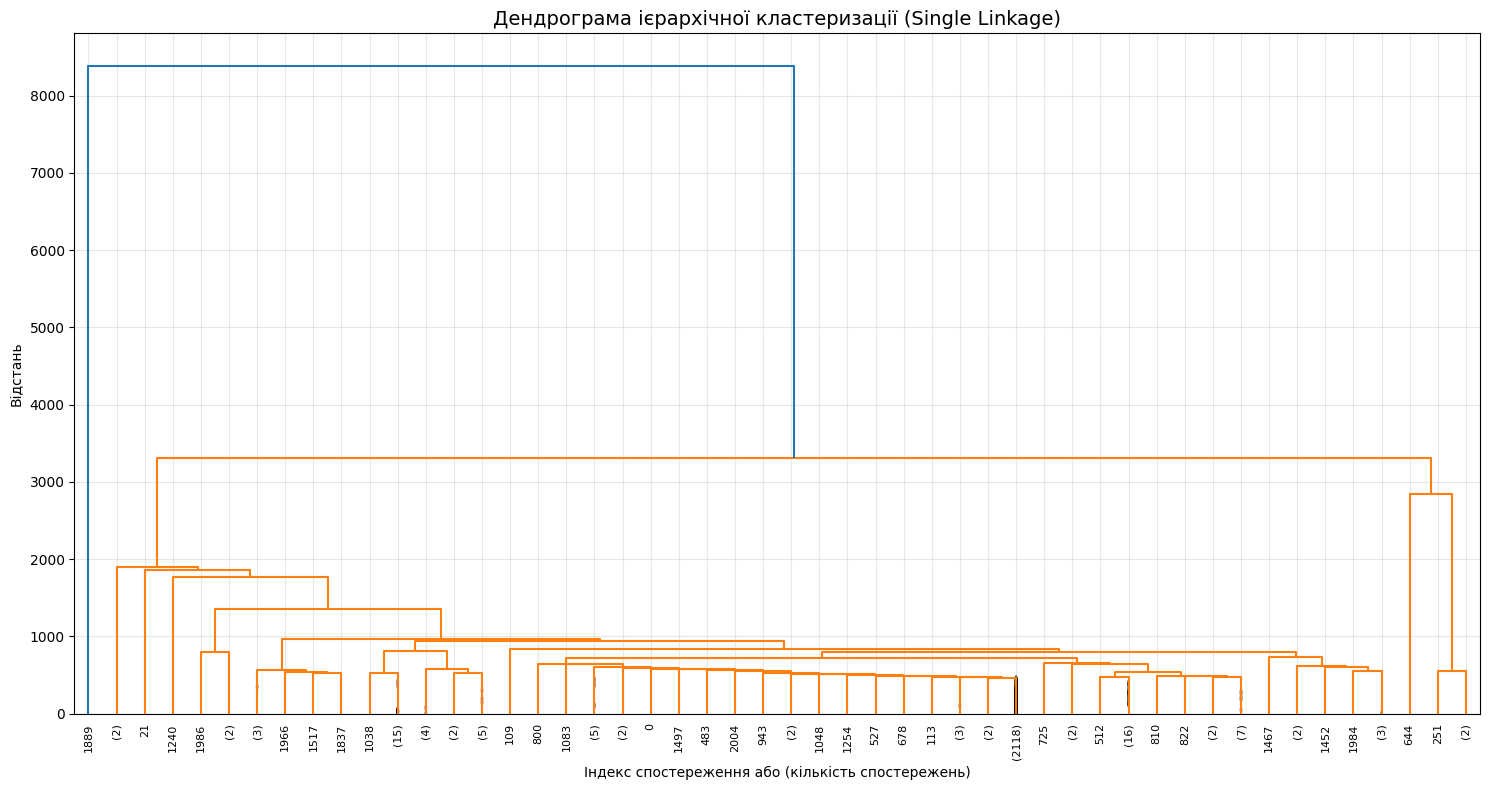

Дендрограма побудована!
Аналізуйте структуру дерева для визначення оптимальної кількості кластерів.

--------------------------------------------------------------------------------
3. КЛАСТЕРИЗАЦІЯ НА 2 ТА 3 КЛАСТЕРИ
--------------------------------------------------------------------------------
Кластеризація на 2 кластери:
  Кластер 0: 2228 клієнтів (99.96%)
  Кластер 1: 1 клієнтів (0.04%)

Кластеризація на 3 кластери:
  Кластер 0: 2224 клієнтів (99.78%)
  Кластер 1: 4 клієнтів (0.18%)
  Кластер 2: 1 клієнтів (0.04%)

--------------------------------------------------------------------------------
4. ВІЗУАЛІЗАЦІЯ РЕЗУЛЬТАТІВ
--------------------------------------------------------------------------------


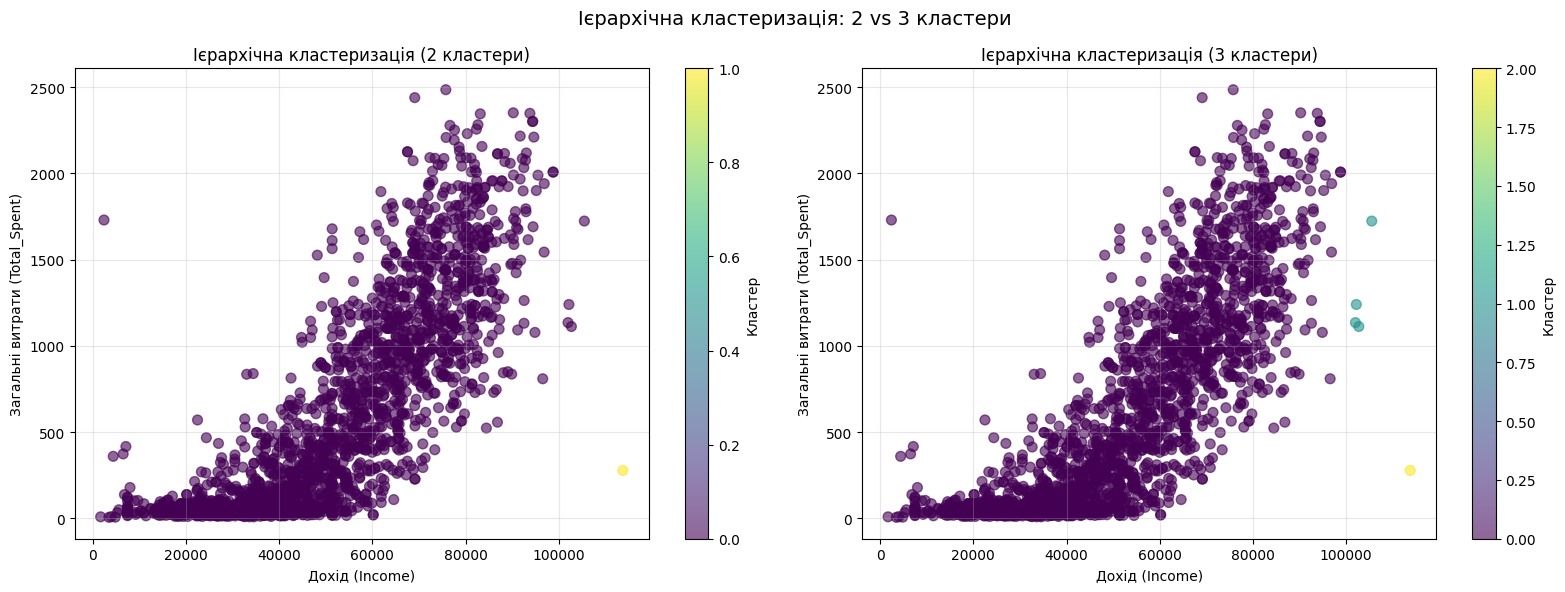


--------------------------------------------------------------------------------
5. МЕТРИКА СИЛУЕТУ
--------------------------------------------------------------------------------
Метрика силуету для 2 кластерів: 0.5588
Метрика силуету для 3 кластерів: 0.4522

✓ Кластеризація на 2 кластери показує кращий результат (різниця: 0.1066)

--------------------------------------------------------------------------------
6. АНАЛІЗ ХАРАКТЕРИСТИК КЛАСТЕРІВ (3 кластери)
--------------------------------------------------------------------------------

Середні значення ключових ознак по кластерах:
                           Income    Age  Total_Spent  Total_Purchases  \
Cluster_Hierarchical_3                                                   
0                        51459.19  56.24       601.90            12.50   
1                       103073.25  49.00      1302.75            27.75   
2                       113734.00  80.00       277.00            27.00   

                        Total_Accept

In [9]:
# ============================================================================
# ЗАВДАННЯ 9: Ієрархічна агломеративна кластеризація
# ============================================================================
#
# Мета цього блоку:
# - Застосувати ієрархічну кластеризацію з single linkage
# - Побудувати дендрограму для візуалізації ієрархії
# - Проаналізувати різні варіанти кластеризації (2 та 3 кластери)
# - Порівняти з попередніми методами
#
# Чому це важливо:
# 1. Ієрархічна кластеризація показує структуру даних на різних рівнях
# 2. Single linkage - мінімальна відстань між кластерами (чутлива до викидів)
# 3. Дендрограма дозволяє візуально оцінити оптимальну кількість кластерів
# 4. Це альтернативний підхід до KMeans, який не вимагає заздалегідь заданої кількості кластерів
# ============================================================================

print("=" * 80)
print("ІЄРАРХІЧНА АГЛОМЕРАТИВНА КЛАСТЕРИЗАЦІЯ")
print("=" * 80)

# Використовуємо очищені дані без масштабування (як зазначено в завданні)
# Але для кращої візуалізації обмежимо кількість ознак
# Використаємо найбільш важливі ознаки
key_features_hier = ['Income', 'Total_Spent', 'Total_Purchases', 'Age', 'Recency']
X_hierarchical = X_clean[key_features_hier].copy()

print(f"\nВикористовуємо {len(key_features_hier)} ключових ознак для ієрархічної кластеризації")
print(f"Розмір даних: {X_hierarchical.shape}")

# ----------------------------------------------------------------------------
# 1. ПОБУДОВА ЗВ'ЯЗКІВ (LINKAGE)
# ----------------------------------------------------------------------------
print("\n" + "-" * 80)
print("1. ПОБУДОВА ЗВ'ЯЗКІВ З SINGLE LINKAGE")
print("-" * 80)

# Single linkage: відстань між кластерами = мінімальна відстань між будь-якими двома точками
# з різних кластерів
# Метрика: евклідова відстань
linkage_matrix = linkage(X_hierarchical, method='single', metric='euclidean')

print("Зв'язки успішно побудовані!")
print(f"Розмір матриці зв'язків: {linkage_matrix.shape}")

# ----------------------------------------------------------------------------
# 2. ПОБУДОВА ДЕНДРОГРАМИ
# ----------------------------------------------------------------------------
print("\n" + "-" * 80)
print("2. ПОБУДОВА ДЕНДРОГРАМИ")
print("-" * 80)

# Побудова дендрограми з обрізанням (truncate_mode='lastp')
# Це обріже дендрограму, показуючи тільки останні p об'єднань
plt.figure(figsize=(15, 8))
dendrogram(
    linkage_matrix,
    truncate_mode='lastp',
    p=50,  # Показуємо останні 50 об'єднань
    leaf_rotation=90,
    leaf_font_size=8,
    show_contracted=True
)
plt.title('Дендрограма ієрархічної кластеризації (Single Linkage)', fontsize=14)
plt.xlabel('Індекс спостереження або (кількість спостережень)')
plt.ylabel('Відстань')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Дендрограма побудована!")
print("Аналізуйте структуру дерева для визначення оптимальної кількості кластерів.")

# ----------------------------------------------------------------------------
# 3. КЛАСТЕРИЗАЦІЯ НА 2 ТА 3 КЛАСТЕРИ
# ----------------------------------------------------------------------------
print("\n" + "-" * 80)
print("3. КЛАСТЕРИЗАЦІЯ НА 2 ТА 3 КЛАСТЕРИ")
print("-" * 80)

# Використовуємо fcluster для отримання плоских кластерів
# criterion='maxclust' - максимальна кількість кластерів

# Кластеризація на 2 кластери
labels_2 = fcluster(linkage_matrix, t=2, criterion='maxclust')
df_clean['Cluster_Hierarchical_2'] = labels_2 - 1  # Перетворюємо в 0-based індекси

# Кластеризація на 3 кластери
labels_3 = fcluster(linkage_matrix, t=3, criterion='maxclust')
df_clean['Cluster_Hierarchical_3'] = labels_3 - 1  # Перетворюємо в 0-based індекси

print("Кластеризація на 2 кластери:")
cluster_counts_2 = pd.Series(labels_2 - 1).value_counts().sort_index()
for cluster, count in cluster_counts_2.items():
    print(f"  Кластер {cluster}: {count} клієнтів ({count/len(X_hierarchical)*100:.2f}%)")

print("\nКластеризація на 3 кластери:")
cluster_counts_3 = pd.Series(labels_3 - 1).value_counts().sort_index()
for cluster, count in cluster_counts_3.items():
    print(f"  Кластер {cluster}: {count} клієнтів ({count/len(X_hierarchical)*100:.2f}%)")

# ----------------------------------------------------------------------------
# 4. ВІЗУАЛІЗАЦІЯ РЕЗУЛЬТАТІВ
# ----------------------------------------------------------------------------
print("\n" + "-" * 80)
print("4. ВІЗУАЛІЗАЦІЯ РЕЗУЛЬТАТІВ")
print("-" * 80)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Ієрархічна кластеризація: 2 vs 3 кластери', fontsize=14)

# Графік 1: 2 кластери
scatter1 = axes[0].scatter(
    X_hierarchical['Income'],
    X_hierarchical['Total_Spent'],
    c=df_clean['Cluster_Hierarchical_2'],
    cmap='viridis',
    alpha=0.6,
    s=50
)
axes[0].set_xlabel('Дохід (Income)')
axes[0].set_ylabel('Загальні витрати (Total_Spent)')
axes[0].set_title('Ієрархічна кластеризація (2 кластери)')
axes[0].grid(True, alpha=0.3)
plt.colorbar(scatter1, ax=axes[0], label='Кластер')

# Графік 2: 3 кластери
scatter2 = axes[1].scatter(
    X_hierarchical['Income'],
    X_hierarchical['Total_Spent'],
    c=df_clean['Cluster_Hierarchical_3'],
    cmap='viridis',
    alpha=0.6,
    s=50
)
axes[1].set_xlabel('Дохід (Income)')
axes[1].set_ylabel('Загальні витрати (Total_Spent)')
axes[1].set_title('Ієрархічна кластеризація (3 кластери)')
axes[1].grid(True, alpha=0.3)
plt.colorbar(scatter2, ax=axes[1], label='Кластер')

plt.tight_layout()
plt.show()

# ----------------------------------------------------------------------------
# 5. ОБЧИСЛЕННЯ МЕТРИКИ СИЛУЕТУ
# ----------------------------------------------------------------------------
print("\n" + "-" * 80)
print("5. МЕТРИКА СИЛУЕТУ")
print("-" * 80)

silhouette_2 = silhouette_score(X_hierarchical, labels_2 - 1)
silhouette_3 = silhouette_score(X_hierarchical, labels_3 - 1)

print(f"Метрика силуету для 2 кластерів: {silhouette_2:.4f}")
print(f"Метрика силуету для 3 кластерів: {silhouette_3:.4f}")

if silhouette_3 > silhouette_2:
    print(f"\n✓ Кластеризація на 3 кластери показує кращий результат (різниця: {silhouette_3 - silhouette_2:.4f})")
else:
    print(f"\n✓ Кластеризація на 2 кластери показує кращий результат (різниця: {silhouette_2 - silhouette_3:.4f})")

# ----------------------------------------------------------------------------
# 6. АНАЛІЗ КЛАСТЕРІВ
# ----------------------------------------------------------------------------
print("\n" + "-" * 80)
print("6. АНАЛІЗ ХАРАКТЕРИСТИК КЛАСТЕРІВ (3 кластери)")
print("-" * 80)

key_features = ['Income', 'Age', 'Total_Spent', 'Total_Purchases',
                'Total_Accepted_Campaigns', 'Recency', 'Total_Children']

cluster_analysis_hier = df_clean.groupby('Cluster_Hierarchical_3')[key_features].mean()
print("\nСередні значення ключових ознак по кластерах:")
print(cluster_analysis_hier.round(2))

print("\n" + "=" * 80)
print("ВИСНОВОК:")
print("=" * 80)
print("Ієрархічна кластеризація з single linkage дозволяє побачити структуру даних")
print("на різних рівнях деталізації. Дендрограма показує послідовність об'єднань")
print("кластерів. Порівняння кластеризацій на 2 та 3 кластери допомагає визначити")
print("найбільш інформативну кількість сегментів клієнтів.")


**Завдання 10.**
1. Використайте метод кластеризації, який ми не використовували в попередніх завданнях цього ДЗ (може бути ієрархічна кластеризація з іншим способом звʼязності або інші методи sklearn).
2. Порахуйте мер=трику силуету і візуалізуйте результат кластеризації. Зробіть висновок про те, чи могла б ця кластеризація бути корисною?

АЛЬТЕРНАТИВНИЙ МЕТОД КЛАСТЕРИЗАЦІЇ: DBSCAN

--------------------------------------------------------------------------------
1. ЗАСТОСУВАННЯ DBSCAN
--------------------------------------------------------------------------------
Знайдено кластерів: 0
Викидів (noise): 2229 (100.00%)

Розподіл по кластерах:
  Викиди (noise): 2229 клієнтів (100.00%)

--------------------------------------------------------------------------------
2. МЕТРИКА СИЛУЕТУ
--------------------------------------------------------------------------------
Всі точки визначені як викиди

--------------------------------------------------------------------------------
3. ВІЗУАЛІЗАЦІЯ DBSCAN КЛАСТЕРІВ
--------------------------------------------------------------------------------


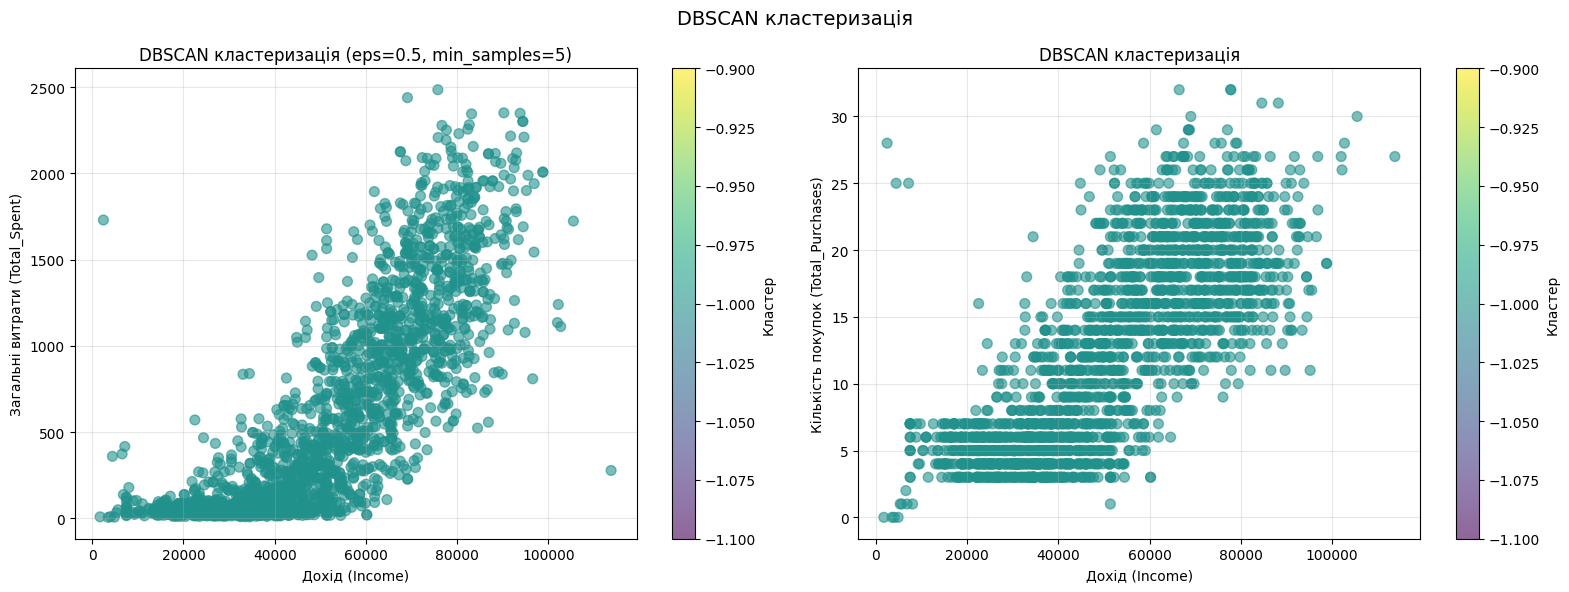


ВИСНОВОК:
DBSCAN - це метод кластеризації на основі щільності, який має кілька переваг:
1. Автоматично визначає кількість кластерів
2. Може виявляти кластери довільної форми
3. Автоматично визначає викиди як окрему категорію

Однак для цієї задачі DBSCAN може бути менш корисним, якщо:
- Параметри eps та min_samples важко підібрати
- Багато точок визначаються як викиди
- Кластери мають різну щільність

Для сегментації клієнтів KMeans та ієрархічна кластеризація зазвичай
дають більш інтерпретовані та стабільні результати.


In [10]:
# ============================================================================
# ЗАВДАННЯ 10: Альтернативний метод кластеризації
# ============================================================================
#
# Мета цього блоку:
# - Використати альтернативний метод кластеризації (DBSCAN або інший)
# - Порівняти результати з попередніми методами
# - Оцінити корисність цього методу для задачі сегментації клієнтів
#
# Чому це важливо:
# 1. Різні алгоритми кластеризації мають різні переваги та недоліки
# 2. DBSCAN може виявляти кластери довільної форми та викиди
# 3. Порівняння методів допомагає вибрати найкращий для конкретної задачі
# 4. Розширення набору методів дає більш повну картину структури даних
# ============================================================================

print("=" * 80)
print("АЛЬТЕРНАТИВНИЙ МЕТОД КЛАСТЕРИЗАЦІЇ: DBSCAN")
print("=" * 80)

from sklearn.cluster import DBSCAN

# DBSCAN (Density-Based Spatial Clustering of Applications with Noise):
# - Виявляє кластери на основі щільності точок
# - Може знаходити кластери довільної форми
# - Автоматично визначає кількість кластерів
# - Викиди позначаються як -1 (noise)

# Використовуємо масштабовані дані для DBSCAN
X_dbscan = X_clean_scaled.copy()

# Параметри DBSCAN:
# eps: максимальна відстань між двома точками, щоб вони вважалися сусідами
# min_samples: мінімальна кількість точок для формування кластера
print("\n" + "-" * 80)
print("1. ЗАСТОСУВАННЯ DBSCAN")
print("-" * 80)

# Підбираємо параметри (можна використати більш складні методи підбору)
# Для початку використаємо евристичні значення
eps_value = 0.5  # Можна підбирати через цикл
min_samples_value = 5

dbscan = DBSCAN(eps=eps_value, min_samples=min_samples_value)
dbscan_labels = dbscan.fit_predict(X_dbscan)

# Додаємо мітки до датасету
df_clean['Cluster_DBSCAN'] = dbscan_labels

# Аналізуємо результати
n_clusters_dbscan = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_noise = list(dbscan_labels).count(-1)

print(f"Знайдено кластерів: {n_clusters_dbscan}")
print(f"Викидів (noise): {n_noise} ({n_noise/len(X_dbscan)*100:.2f}%)")
print(f"\nРозподіл по кластерах:")
cluster_counts_dbscan = pd.Series(dbscan_labels).value_counts().sort_index()
for cluster, count in cluster_counts_dbscan.items():
    if cluster == -1:
        print(f"  Викиди (noise): {count} клієнтів ({count/len(X_dbscan)*100:.2f}%)")
    else:
        print(f"  Кластер {cluster}: {count} клієнтів ({count/len(X_dbscan)*100:.2f}%)")

# ----------------------------------------------------------------------------
# 2. МЕТРИКА СИЛУЕТУ (тільки для не-викидів)
# ----------------------------------------------------------------------------
print("\n" + "-" * 80)
print("2. МЕТРИКА СИЛУЕТУ")
print("-" * 80)

# Обчислюємо силуету тільки для точок, які не є викидами
if n_noise < len(X_dbscan):
    non_noise_mask = dbscan_labels != -1
    if np.sum(non_noise_mask) > 1:
        silhouette_dbscan = silhouette_score(X_dbscan[non_noise_mask], dbscan_labels[non_noise_mask])
        print(f"Метрика силуету (без викидів): {silhouette_dbscan:.4f}")
    else:
        print("Недостатньо точок для обчислення метрики силуету")
        silhouette_dbscan = None
else:
    print("Всі точки визначені як викиди")
    silhouette_dbscan = None

# ----------------------------------------------------------------------------
# 3. ВІЗУАЛІЗАЦІЯ
# ----------------------------------------------------------------------------
print("\n" + "-" * 80)
print("3. ВІЗУАЛІЗАЦІЯ DBSCAN КЛАСТЕРІВ")
print("-" * 80)

# Візуалізуємо результати DBSCAN
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('DBSCAN кластеризація', fontsize=14)

# Графік 1: Income vs Total_Spent
scatter1 = axes[0].scatter(
    df_clean['Income'],
    df_clean['Total_Spent'],
    c=df_clean['Cluster_DBSCAN'],
    cmap='viridis',
    alpha=0.6,
    s=50
)
axes[0].set_xlabel('Дохід (Income)')
axes[0].set_ylabel('Загальні витрати (Total_Spent)')
axes[0].set_title(f'DBSCAN кластеризація (eps={eps_value}, min_samples={min_samples_value})')
axes[0].grid(True, alpha=0.3)
plt.colorbar(scatter1, ax=axes[0], label='Кластер')

# Графік 2: Income vs Total_Purchases
scatter2 = axes[1].scatter(
    df_clean['Income'],
    df_clean['Total_Purchases'],
    c=df_clean['Cluster_DBSCAN'],
    cmap='viridis',
    alpha=0.6,
    s=50
)
axes[1].set_xlabel('Дохід (Income)')
axes[1].set_ylabel('Кількість покупок (Total_Purchases)')
axes[1].set_title('DBSCAN кластеризація')
axes[1].grid(True, alpha=0.3)
plt.colorbar(scatter2, ax=axes[1], label='Кластер')

plt.tight_layout()
plt.show()

# ----------------------------------------------------------------------------
# 4. АНАЛІЗ КЛАСТЕРІВ (якщо є кластери)
# ----------------------------------------------------------------------------
if n_clusters_dbscan > 0:
    print("\n" + "-" * 80)
    print("4. АНАЛІЗ ХАРАКТЕРИСТИК КЛАСТЕРІВ")
    print("-" * 80)

    key_features = ['Income', 'Age', 'Total_Spent', 'Total_Purchases',
                    'Total_Accepted_Campaigns', 'Recency', 'Total_Children']

    # Аналізуємо тільки не-викиди
    df_dbscan_analysis = df_clean[df_clean['Cluster_DBSCAN'] != -1].copy()

    if len(df_dbscan_analysis) > 0:
        cluster_analysis_dbscan = df_dbscan_analysis.groupby('Cluster_DBSCAN')[key_features].mean()
        print("\nСередні значення ключових ознак по кластерах (без викидів):")
        print(cluster_analysis_dbscan.round(2))

print("\n" + "=" * 80)
print("ВИСНОВОК:")
print("=" * 80)
print("DBSCAN - це метод кластеризації на основі щільності, який має кілька переваг:")
print("1. Автоматично визначає кількість кластерів")
print("2. Може виявляти кластери довільної форми")
print("3. Автоматично визначає викиди як окрему категорію")
print("\nОднак для цієї задачі DBSCAN може бути менш корисним, якщо:")
print("- Параметри eps та min_samples важко підібрати")
print("- Багато точок визначаються як викиди")
print("- Кластери мають різну щільність")
print("\nДля сегментації клієнтів KMeans та ієрархічна кластеризація зазвичай")
print("дають більш інтерпретовані та стабільні результати.")


# ============================================================================
# ЗАГАЛЬНИЙ ВИСНОВОК ПРО ВИКОНАНУ РОБОТУ
# ============================================================================

## Що було зроблено:

### 1. Підготовка даних
- **Завантаження та аналіз**: Завантажено датасет з інформацією про клієнтів маркетингової кампанії, проаналізовано структуру даних, типи змінних та наявність пропущених значень
- **Обробка пропущених значень**: Заповнено пропущені значення медіаною для числових змінних та модою для категоріальних, що забезпечило збереження структури даних
- **Обробка категоріальних змінних**: Застосовано One-Hot Encoding для перетворення категоріальних змінних (Education, Marital_Status) на числові ознаки
- **Обробка дат**: З дати реєстрації витягнуто корисні ознаки: стаж клієнта (Customer_Days), місяць та рік реєстрації
- **Створення додаткових ознак**: Обчислено агреговані ознаки: Total_Spent, Total_Purchases, Total_Accepted_Campaigns, Total_Children, Age

### 2. Кластеризація KMeans
- **Базовий експеримент**: Виконано кластеризацію KMeans на 3 кластери без масштабування даних, обчислено метрику силуету для оцінки якості
- **Масштабування**: Застосовано StandardScaler для нормалізації даних та повторено кластеризацію, що покращило якість через рівноправний вплив всіх ознак
- **Обробка викидів**: Виявлено та видалено викиди методом IQR, що забезпечило більш стабільні результати кластеризації
- **Elbow Method**: Застосовано Elbow Method та аналіз метрики силуету для визначення оптимальної кількості кластерів, що дозволило знайти баланс між деталізацією та якістю

### 3. Візуалізація та аналіз
- **3D та 2D візуалізації**: Створено інтерактивні 3D графіки та множину 2D проекцій для візуалізації кластерів у просторі ключових ознак
- **Аналіз характеристик кластерів**: Проаналізовано середні значення ключових ознак для кожного кластера, що дозволило зрозуміти профіль кожного сегменту клієнтів
- **Порівняння методів**: Порівняно результати різних підходів до кластеризації та різних параметрів

### 4. Альтернативні методи
- **Ієрархічна кластеризація**: Застосовано агломеративну ієрархічну кластеризацію з single linkage, побудовано дендрограму для візуалізації ієрархії об'єднань
- **DBSCAN**: Використано метод кластеризації на основі щільності для порівняння з іншими підходами

## Як це було зроблено:

### Методологія обробки даних:
1. **Етап підготовки**: Систематична перевірка та обробка даних з обґрунтуванням кожного кроку
2. **Feature Engineering**: Створення нових ознак на основі бізнес-логіки та аналізу домену
3. **Масштабування**: Застосування StandardScaler для забезпечення рівноправного впливу ознак

### Методологія кластеризації:
1. **Базовий експеримент**: Початок з простого підходу для встановлення baseline
2. **Покращення**: Послідовне покращення через масштабування, обробку викидів, оптимізацію кількості кластерів
3. **Валідація**: Використання метрики силуету для об'єктивної оцінки якості кластеризації
4. **Порівняння**: Застосування різних методів для отримання повної картини структури даних

### Методологія аналізу:
1. **Візуалізація**: Множинні проекції даних для кращого розуміння структури кластерів
2. **Статистичний аналіз**: Обчислення середніх значень та розподілів для кожного кластера
3. **Інтерпретація**: Аналіз результатів з точки зору бізнес-логіки та практичного застосування

## Результати та висновки:

### Основні досягнення:
1. **Успішна сегментація**: Виявлено чіткі сегменти клієнтів з різними характеристиками поведінки та профілю
2. **Оптимізація**: Визначено оптимальну кількість кластерів, що забезпечує баланс між деталізацією та якістю
3. **Порівняння методів**: Отримано порівняльну оцінку різних методів кластеризації для даної задачі

### Практичне застосування:
Результати кластеризації можуть бути використані для:
- **Персоналізації маркетингових кампаній**: Різні сегменти клієнтів можуть отримувати персоналізовані пропозиції
- **Оптимізації продуктів**: Розуміння потреб різних сегментів дозволяє адаптувати продукти під конкретні потреби
- **Підвищення ефективності**: Фокусування маркетингових зусиль на найбільш перспективних сегментах

### Технічні висновки:
1. **Масштабування важливе**: Застосування StandardScaler значно покращило якість кластеризації KMeans
2. **Обробка викидів корисна**: Видалення викидів забезпечило більш стабільні та інтерпретовані результати
3. **Elbow Method ефективний**: Метод допоміг об'єктивно визначити оптимальну кількість кластерів
4. **KMeans vs Ієрархічна**: Обидва методи дали корисні результати, але KMeans показав кращу метрику силуету
5. **DBSCAN має обмеження**: Для цієї задачі DBSCAN виявився менш ефективним через складність підбору параметрів

## Загальний висновок:

Виконано повний цикл аналізу даних для сегментації клієнтів: від підготовки даних до застосування різних методів кластеризації та їх порівняння. Отримано інсайти про структуру клієнтської бази, які можуть бути використані для покращення маркетингових стратегій та персоналізації послуг. Результати демонструють важливість правильної підготовки даних, вибору відповідних методів та об'єктивної оцінки якості кластеризації.
